# Phase D - Nhan cam xuc tu giong noi (SER) tren MEAD

Muc dich: video dai (vai phut) co cam xuc thay doi theo loi noi -> tu doan cam xuc tu audio de sinh `TIMELINE`
cho Phase C, thay vi chon tay.

* Du lieu: mel da tien xu ly trong `phaseB_ready/<speaker>.npz` (cung cong thuc AutoVC, chuan hoa bang
  `MEAN_STD_AUTOVC_RETRAIN_MEL_AU.txt`), **cung cach chia speaker** voi Phase B (33 train / 4 val / 4 test) ->
  danh gia tren nguoi chua tung nghe.
* Nhan: 8 cam xuc MEAD + muc do 1..3 (neutral chi co muc 1).
* Mo hinh `SERNet` (~0.7M tham so): Conv1d gian no -> attentive statistics pooling -> (8 nhan, muc 1..3).
* Train tren doan cat ngau nhien 2.5 s (giong luc dung: cua so truot 2.5 s), danh gia muc clip bang trung binh
  xac suat cac cua so.
* Cell 6 (tuy chon): so voi model co san **emotion2vec+** tren cung audio MEAD cua speaker test.

| Cell | Noi dung |
| :--- | :--- |
| 1 | Cau hinh |
| 2 | Mount, repo, thu vien |
| 3 | Nap du lieu theo split |
| 4 | Train (luu model tot nhat theo UAR tren val) |
| 5 | Danh gia tren test: accuracy, UAR, ma tran nham lan, sai so muc |
| 6 | (Tuy chon) So sanh voi emotion2vec+ |

**Ket qua luu o** `student_a2l/ser_mead/`: `ser_best.pth` (tot nhat theo val), `ser_last.pth` (epoch moi nhat, de
train tiep khi Colab bi ngat: chay lai tu dau, `RESUME = True`), `ser_history.json`, `ser_test_eval.json`,
`ser_confusion_test.png`, `ser_vs_emotion2vec.json`.

## Cell 1 - Cau hinh

In [1]:
import os, sys, json, time, subprocess, tarfile, random
from pathlib import Path
import numpy as np

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/hien087585/EXPRESSIVE-2D-CHARACTER-ANIMATION.git'
REPO_DIR = Path('/content/MakeItTalk')
DRIVE    = Path('/content/drive/MyDrive/DAT301m/Data_student')
MEAD_SRC = Path('/content/drive/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD')
LIB_DIR  = Path('/content')
_T = os.environ.get('PHASED_TEST_ROOT')           # chi dung khi chay thu ngoai Colab
if _T:
    REPO_DIR, DRIVE, MEAD_SRC, LIB_DIR = Path(_T) / 'repo', Path(_T) / 'drive', Path(_T) / 'mead', Path(_T)
READY = DRIVE / 'Data_emotion_mead_task_b' / 'phaseB_ready'
OUT   = DRIVE / 'student_a2l' / 'ser_mead'

CFG = dict(
    crop=156,              # 2.5 s mel (62.5 khung/giay)
    eval_hop=31,           # cua so truot khi danh gia clip (0.5 s)
    batch=128, epochs=25, steps_per_epoch=600,
    lr=1e-3, weight_decay=1e-2, label_smoothing=0.1,
    lambda_level=0.3,      # trong so loss hoi quy muc 1..3 (chi clip khac neutral)
    ch=192, drop=0.3,
    spec_aug=dict(freq_masks=2, freq_w=10, time_masks=2, time_w=20, gain_std=0.2),
    seed=0,
)
RESUME = True              # Colab bi ngat -> chay lai tu dau notebook, Cell 4 tu train tiep tu epoch da luu
if _T:
    CFG.update(epochs=2, steps_per_epoch=20, batch=16)

## Cell 1b - Ma nguon `ser_lib.py`, `avatar_lib.py` (khong can sua)

In [2]:
SER_LIB_SOURCE = '"""Nhan cam xuc tu giong noi (Speech Emotion Recognition) -> timeline bieu cam cho Phase C.\n\n* SERNet: mo hinh nho tu train tren audio MEAD (mel AutoVC chuan hoa, 8 nhan + muc do 1..3).\n* Emotion2VecSER: boc model co san emotion2vec+ (FunASR), 9 nhan -> quy ve 8 nhan MEAD.\n* probs_to_timeline: xac suat theo cua so -> cac doan cam xuc on dinh (Viterbi phat doi nhan + do dai toi thieu)\n  -> danh sach moc [(t, spec)] dung truc tiep lam TIMELINE.\n"""\nimport numpy as np\n\nEMO_NAMES = [\'neutral\', \'angry\', \'disgusted\', \'fear\', \'happy\', \'sad\', \'surprised\', \'contempt\']\nFPS_MEL = 62.5\n\n\n# ============================================================================= mo hinh tu train (MEAD)\ndef build_sernet(n_mels=80, n_cls=8, ch=192, drop=0.3):\n    import torch\n    import torch.nn as nn\n\n    class SERNet(nn.Module):\n        """Conv1d (gian no) tren mel -> attentive statistics pooling -> phan loai 8 nhan + hoi quy muc 1..3."""\n\n        def __init__(self):\n            super().__init__()\n            def blk(i, o, k, d):\n                return nn.Sequential(nn.Conv1d(i, o, k, padding=d * (k - 1) // 2, dilation=d), nn.BatchNorm1d(o), nn.ReLU())\n            self.body = nn.Sequential(blk(n_mels, ch, 5, 1), blk(ch, ch, 3, 2), blk(ch, ch, 3, 3), blk(ch, ch, 3, 4),\n                                      blk(ch, 2 * ch, 1, 1))\n            self.att = nn.Sequential(nn.Conv1d(2 * ch, 128, 1), nn.Tanh(), nn.Conv1d(128, 1, 1))\n            self.fc = nn.Sequential(nn.Linear(4 * ch, 256), nn.ReLU(), nn.Dropout(drop))\n            self.cls = nn.Linear(256, n_cls)\n            self.lvl = nn.Linear(256, 1)\n            self.cfg = dict(n_mels=n_mels, n_cls=n_cls, ch=ch, drop=drop)\n\n        def forward(self, x):                        # x: (B, T, 80) mel chuan hoa\n            h = self.body(x.transpose(1, 2))         # (B, C, T)\n            a = torch.softmax(self.att(h), dim=-1)   # (B, 1, T)\n            mu = (h * a).sum(-1)\n            sd = ((h - mu[..., None]) ** 2 * a).sum(-1).clamp_min(1e-6).sqrt()\n            z = self.fc(torch.cat([mu, sd], 1))\n            return self.cls(z), 1.0 + 2.0 * torch.sigmoid(self.lvl(z)[:, 0])   # logits, muc 1..3\n\n    return SERNet()\n\n\ndef load_sernet(path, device=\'cpu\'):\n    import torch\n    ck = torch.load(str(path), map_location=\'cpu\', weights_only=False)\n    m = build_sernet(**ck[\'cfg\'])\n    m.load_state_dict(ck[\'state_dict\'])\n    return m.to(device).eval(), ck\n\n\ndef sernet_windows(model, mel_norm, win=156, hop=31, device=\'cpu\', batch=256):\n    """mel chuan hoa (T, 80) -> (tam cua so giay (N,), xac suat (N, 8), muc (N,)). Cua so ngan hon win duoc dem."""\n    import torch\n    T = len(mel_norm)\n    if T < win:\n        mel_norm = np.concatenate([mel_norm, np.repeat(mel_norm.min(0, keepdims=True), win - T, 0)], 0)\n        T = win\n    st = list(range(0, T - win + 1, hop))\n    if st[-1] != T - win:\n        st.append(T - win)\n    P, L = [], []\n    with torch.no_grad():\n        for i in range(0, len(st), batch):\n            idx = np.array(st[i:i + batch])[:, None] + np.arange(win)\n            x = torch.from_numpy(mel_norm[idx].astype(np.float32)).to(device)\n            lg, lv = model(x)\n            P.append(torch.softmax(lg, -1).cpu().numpy()); L.append(lv.cpu().numpy())\n    centers = (np.array(st) + win / 2) / FPS_MEL\n    return centers, np.concatenate(P), np.concatenate(L)\n\n\n# ============================================================================= emotion2vec+ (co san)\nE2V_MAP = {\'angry\': \'angry\', \'disgusted\': \'disgusted\', \'fearful\': \'fear\', \'happy\': \'happy\', \'neutral\': \'neutral\',\n           \'sad\': \'sad\', \'surprised\': \'surprised\', \'other\': \'neutral\', \'unknown\': \'neutral\'}\n\n\nclass Emotion2VecSER:\n    """emotion2vec+ (FunASR). Tai model lan dau (~1 GB voi ban large). hub: \'hf\' (HuggingFace) hoac \'ms\' (ModelScope)."""\n\n    def __init__(self, size=\'large\', device=\'cuda\', hub=\'hf\'):\n        from funasr import AutoModel\n        err = None\n        for h in ([hub] + [x for x in (\'hf\', \'ms\') if x != hub]):          # HuggingFace loi -> thu ModelScope\n            name = (\'emotion2vec/emotion2vec_plus_%s\' if h == \'hf\' else \'iic/emotion2vec_plus_%s\') % size\n            try:\n                self.m = AutoModel(model=name, hub=h, device=device, disable_update=True, disable_pbar=True,\n                                   disable_log=True)\n                break\n            except Exception as e:                                         # thu nguon khac\n                err = e\n        else:\n            raise RuntimeError(\'Khong tai duoc emotion2vec+: %r\' % err)\n\n    def predict(self, y16k):\n        """1 doan audio (float32, 16 kHz) -> xac suat (8,) theo EMO_NAMES."""\n        r = self.m.generate(np.asarray(y16k, np.float32), granularity=\'utterance\', extract_embedding=False,\n                            disable_pbar=True)[0]\n        p = np.zeros(8, np.float32)\n        for lab, sc in zip(r[\'labels\'], r[\'scores\']):\n            k = E2V_MAP.get(str(lab).split(\'/\')[-1].strip().lower())\n            if k is not None:\n                p[EMO_NAMES.index(k)] += float(sc)\n        return p / max(p.sum(), 1e-8)\n\n    def windows(self, y, win=2.5, hop=0.5, sr=16000):\n        n, h = int(win * sr), int(hop * sr)\n        st = list(range(0, max(len(y) - n, 0) + 1, h)) or [0]\n        P = np.stack([self.predict(y[s:s + n]) for s in st])\n        return (np.array(st) + min(n, len(y)) / 2) / sr, P\n\n\n# ============================================================================= xac suat -> timeline\ndef window_energy(y, centers, win=2.5, sr=16000):\n    """Am luong (dB so voi doan to nhat) cua tung cua so -> nhan dien doan im lang."""\n    out = []\n    for c in centers:\n        a, b = int(max(0, (c - win / 2) * sr)), int(min(len(y), (c + win / 2) * sr))\n        out.append(10 * np.log10(np.mean(y[a:b] ** 2) + 1e-10) if b > a else -100.0)\n    out = np.array(out)\n    return out - out.max()\n\n\ndef viterbi(logp, switch_penalty):\n    """logp (N, K). Chuoi nhan toi uu khi moi lan doi nhan bi tru `switch_penalty`."""\n    N, K = logp.shape\n    score = logp[0].copy(); back = np.zeros((N, K), int)\n    for t in range(1, N):\n        stay = score; move = score.max() - switch_penalty\n        best_prev = np.where(stay >= move, np.arange(K), score.argmax())\n        score = np.maximum(stay, move) + logp[t]; back[t] = best_prev\n    path = np.zeros(N, int); path[-1] = score.argmax()\n    for t in range(N - 1, 0, -1):\n        path[t - 1] = back[t, path[t]]\n    return path\n\n\nAUTO_EMOTICON = {\'happy\': \':d\', \'sad\': \':~\', \'angry\': \'>-|\', \'surprised\': \':o\', \'fear\': \';-s\', \'disgusted\': \':-r\'}\n\n\ndef probs_to_timeline(centers, P, energy_db=None, levels=None, duration=None, smooth=3, neutral_weight=0.7,\n                      switch_penalty=3.0, min_dur=2.0, silence_db=-35.0, trans=0.4, emoticon=True,\n                      emoticon_level=2.5, allowed=None):\n    """centers (N,) giay, P (N, 8) xac suat theo EMO_NAMES, levels (N,) muc 1..3 neu mo hinh co du doan muc.\n    -> (keys [(t, spec)], segments [dict(start, end, emo, level, conf)])."""\n    P = np.asarray(P, np.float64).copy()\n    if allowed is not None:                                   # chi cho phep mot so nhan\n        mask = np.array([e in allowed for e in EMO_NAMES], float); P = P * mask\n    P[:, 0] *= neutral_weight                                 # giam thien huong \'neutral\' cua mo hinh\n    if energy_db is not None:                                 # doan im lang -> nghieng ve neutral\n        sil = energy_db < silence_db\n        P[sil] = 0.0; P[sil, 0] = 1.0\n    P /= P.sum(1, keepdims=True) + 1e-12\n    if smooth > 1:\n        k = np.ones(smooth) / smooth\n        P = np.stack([np.convolve(np.pad(P[:, j], (smooth // 2, smooth - 1 - smooth // 2), mode=\'edge\'), k, \'valid\')\n                      for j in range(P.shape[1])], 1)\n    path = viterbi(np.log(P + 1e-6), switch_penalty)\n    hop = float(np.median(np.diff(centers))) if len(centers) > 1 else 1.0\n    duration = duration if duration is not None else float(centers[-1] + hop)\n    # doan lien tiep cung nhan\n    segs, a = [], 0\n    for i in range(1, len(path) + 1):\n        if i == len(path) or path[i] != path[a]:\n            segs.append([a, i, int(path[a])]); a = i\n    # gop doan qua ngan vao doan ben canh co xac suat cao hon\n    changed = True\n    while changed and len(segs) > 1:\n        changed = False\n        for j, (a, b, e) in enumerate(segs):\n            if (b - a) * hop < min_dur:\n                nb = [k for k in (j - 1, j + 1) if 0 <= k < len(segs)]\n                k = max(nb, key=lambda k: P[a:b, segs[k][2]].mean())\n                if k < j:\n                    segs[k][1] = b\n                else:\n                    segs[k][0] = a\n                segs.pop(j); changed = True\n                break\n        merged = []                                              # noi cac doan lien ke cung nhan\n        for s in segs:\n            if merged and merged[-1][2] == s[2]:\n                merged[-1][1] = s[1]\n            else:\n                merged.append(s)\n        segs = merged\n    out, keys = [], []\n    for j, (a, b, e) in enumerate(segs):\n        t0 = 0.0 if j == 0 else 0.5 * (centers[a - 1] + centers[a])\n        t1 = duration if j == len(segs) - 1 else 0.5 * (centers[b - 1] + centers[b])\n        conf = float(P[a:b, e].mean())\n        if levels is not None:\n            lvl = float(np.clip(np.mean(levels[a:b]), 1.0, 3.0))\n        else:\n            lvl = float(1.0 + 2.0 * np.clip((conf - 0.4) / 0.5, 0, 1))\n        name = EMO_NAMES[e]\n        spec = \'neutral\' if name == \'neutral\' else (\n            AUTO_EMOTICON[name] if emoticon and lvl >= emoticon_level and name in AUTO_EMOTICON else (name, round(lvl, 2)))\n        t0, t1 = float(t0), float(t1)\n        out.append(dict(start=round(t0, 2), end=round(t1, 2), emo=name, level=round(lvl, 2), conf=round(conf, 3),\n                        spec=spec))\n        ts = t0 if j == 0 else min(t0 + trans, 0.5 * (t0 + t1))    # chuyen dan trong `trans` giay dau doan\n        keys.append((round(ts, 3), spec))                          # giu nguyen tu ts den het doan\n        keys.append((round(t1 if j < len(segs) - 1 else duration + 1.0, 3), spec))\n    return keys, out\n\n\ndef plot_timeline(centers, P, segments, out_png, title=\'\'):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    cols = [\'#9aa0a6\', \'#d93025\', \'#188038\', \'#8430ce\', \'#f9ab00\', \'#1a73e8\', \'#e8710a\', \'#795548\']\n    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.2), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))\n    ax1.stackplot(centers, np.asarray(P).T, colors=cols, labels=EMO_NAMES, alpha=0.85)\n    ax1.set_ylim(0, 1); ax1.set_ylabel(\'xac suat\'); ax1.legend(loc=\'upper left\', bbox_to_anchor=(1.0, 1.0), fontsize=8)\n    ax1.set_title(title, fontsize=10)\n    for s in segments:\n        c = cols[EMO_NAMES.index(s[\'emo\'])]\n        ax2.barh(0, s[\'end\'] - s[\'start\'], left=s[\'start\'], color=c, edgecolor=\'white\')\n        if s[\'end\'] - s[\'start\'] > 1.2:\n            ax2.text(0.5 * (s[\'start\'] + s[\'end\']), 0, \'%s %.1f\' % (s[\'emo\'], s[\'level\']), ha=\'center\', va=\'center\',\n                     fontsize=7, color=\'white\')\n    ax2.set_yticks([]); ax2.set_xlabel(\'giay\'); ax2.set_xlim(0, segments[-1][\'end\'])\n    fig.tight_layout(); fig.savefig(out_png, dpi=110); plt.close(fig)\n    return out_png\n\n\ndef apply_edits(keys, edits, trans=0.4):\n    """Sua tay timeline tu dong: edits = [(t_bat_dau, t_ket_thuc, spec)]. Ngoai doan sua giu nguyen."""\n    def active(ks, t):\n        before = [k for k in ks if k[0] <= t]\n        return before[-1][1] if before else ks[0][1]\n    for a, b, spec in sorted(edits, key=lambda e: e[0]):\n        pa, pb = active(keys, a), active(keys, b)\n        keys = ([k for k in keys if k[0] < a - trans] + [(max(a - trans, 0.0), pa), (a, spec), (b, spec),\n                (b + trans, pb)] + [k for k in keys if k[0] > b + trans])\n    return sorted(keys, key=lambda k: k[0])\n'
AVATAR_LIB_SOURCE = '"""Thu vien demo Phase C: audio + cam xuc -> landmark (mo hinh Phase B) -> avatar 2D -> video.\n\nDung chung cho notebook phaseC_demo_render.ipynb. Khong phu thuoc facewarp.exe.\n"""\nimport os, json, subprocess, shutil\nfrom pathlib import Path\nimport numpy as np\nimport cv2\nfrom scipy.spatial import Delaunay\nfrom scipy.io import wavfile\nfrom scipy.signal import butter, filtfilt, get_window\n\nEMO_NAMES = [\'neutral\', \'angry\', \'disgusted\', \'fear\', \'happy\', \'sad\', \'surprised\', \'contempt\']\nREGIONS = {\'ham\': range(0, 17), \'may\': range(17, 27), \'mui\': range(27, 36),\n           \'mat\': range(36, 48), \'mieng\': range(48, 68)}\nFPS_MODEL = 62.5\nOUTER_LIP = list(range(48, 60))\nUP_IN, LO_IN = [61, 62, 63], [67, 66, 65]          # cap moi trong tren / duoi (doi dien nhau)\nUP_OUT, LO_OUT = [49, 50, 51, 52, 53], [59, 58, 57, 56, 55]\n\n\n# ----------------------------------------------------------------------------- audio\ndef load_wav_16k(path, tmp_dir=\'/tmp\'):\n    """Doc file audio bat ky (wav/m4a/mp3) -> mono 16 kHz float32 [-1, 1]."""\n    out = os.path.join(tmp_dir, \'_demo_16k.wav\')\n    subprocess.run([\'ffmpeg\', \'-y\', \'-loglevel\', \'error\', \'-i\', str(path), \'-ar\', \'16000\', \'-ac\', \'1\', out], check=True)\n    sr, y = wavfile.read(out)\n    return (y.astype(np.float32) / 32768.0) if y.dtype == np.int16 else y.astype(np.float32)\n\n\ndef _stft(x, n=1024, hop=256):\n    x = np.pad(x, n // 2, mode=\'reflect\')\n    sh = x.shape[:-1] + ((x.shape[-1] - (n - hop)) // hop, n)\n    st = x.strides[:-1] + (hop * x.strides[-1], x.strides[-1])\n    return np.abs(np.fft.rfft(get_window(\'hann\', n, fftbins=True) * np.lib.stride_tricks.as_strided(x, sh, st), n=n).T)\n\n\n_MB = None\n\n\ndef mel_autovc(y):\n    """Cong thuc mel giong luc tien xu ly MEAD (AutoVC, 80 bang, 62.5 khung/giay, khong cat 0-1)."""\n    global _MB\n    if _MB is None:\n        import librosa\n        _MB = librosa.filters.mel(sr=16000, n_fft=1024, fmin=90, fmax=7600, n_mels=80).T\n    b, a = butter(5, 30 / 8000, btype=\'high\')\n    x = filtfilt(b, a, y.astype(np.float64)) * 0.96\n    minl = np.exp(-100 / 20 * np.log(10))\n    return ((20 * np.log10(np.maximum(minl, _stft(x).T @ _MB)) - 16 + 100) / 100).astype(np.float32)\n\n\ndef pitch_shift(y, n_steps):\n    """Doi cao do (bán cung) - minh hoa doi giong don gian, giu nguyen thoi luong."""\n    if not n_steps:\n        return y\n    import librosa, warnings\n    with warnings.catch_warnings():\n        warnings.simplefilter(\'ignore\')\n        return librosa.effects.pitch_shift(y, sr=16000, n_steps=float(n_steps)).astype(np.float32)\n\n\n# ----------------------------------------------------------------------------- cam xuc\ndef parse_mix(mix):\n    """\'happy\' | (\'happy\', 2.5) | {\'happy\': 2.0, \'surprised\': 1.0}  ->  {emo_id: level}.\n    level la so thuc: 0 = trung tinh, 1..3 = cac muc da train (>3 la ngoai suy)."""\n    if mix is None or mix == \'neutral\':\n        return {}\n    if isinstance(mix, str):\n        mix = {mix: 3.0}\n    if isinstance(mix, (tuple, list)):\n        mix = {mix[0]: float(mix[1])}\n    out = {}\n    for k, v in mix.items():\n        e = EMO_NAMES.index(k) if isinstance(k, str) else int(k)\n        if e > 0 and float(v) > 0:\n            out[e] = out.get(e, 0.0) + float(v)\n    return out\n\n\nclass EmotionBank:\n    """Do lech tinh theo (cam xuc, muc) + vector cam xuc cho mo hinh; noi suy muc lien tuc.\n\n    Do lech = data_weight * (trung binh MEAD theo nhan) + (bieu cam hoat hinh thiet ke san, neu co).\n    Neu nhan vat co bieu cam ve tay cho cam xuc do thi dung bieu cam ve tay thay cho ca hai."""\n\n    def __init__(self, off_table, emotion_dim=7, char_expr=None, extra=None, data_weight=1.0):\n        self.off = off_table                     # {(emo, lvl): (136,)} khong gian MEAD\n        self.dim = emotion_dim\n        self.char_expr = char_expr or {}         # {emo: (136,)} bieu cam ve tay, khong gian MEAD, tuong ung muc 3\n        self.extra = extra or {}                 # {emo: (136,)} bieu cam hoat hinh, khong gian MEAD, muc 3\n        self.data_weight = float(data_weight)\n\n    def offset(self, e, l):\n        if e in self.char_expr:                  # bieu cam rieng cua nhan vat: tuyen tinh theo muc\n            return self.char_expr[e] * (l / 3.0)\n        out = self.data_weight * self._data(e, l)\n        if e in self.extra:\n            out = out + self.extra[e] * (l / 3.0)\n        return out\n\n    def _data(self, e, l):\n        pts = [(0.0, np.zeros(136, np.float32))] + [(float(k), self.off[(e, k)]) for k in (1, 2, 3) if (e, k) in self.off]\n        if len(pts) < 2:                         # khong co du lieu cho cam xuc nay\n            return np.zeros(136, np.float32)\n        xs = np.array([p[0] for p in pts]); ys = np.stack([p[1] for p in pts])\n        if l <= xs[-1]:\n            j = np.searchsorted(xs, l)\n            j = min(max(j, 1), len(xs) - 1)\n        else:\n            j = len(xs) - 1                      # ngoai suy tu 2 diem cuoi\n        x0, x1 = xs[j - 1], xs[j]\n        return ys[j - 1] + (ys[j] - ys[j - 1]) * (l - x0) / (x1 - x0)\n\n    def __call__(self, mix):\n        """-> (do lech tinh (136,), vector cam xuc (dim,))"""\n        mix = parse_mix(mix)\n        off = np.zeros(136, np.float32); vec = np.zeros(self.dim, np.float32)\n        for e, l in mix.items():\n            off += self.offset(e, l)\n            vec[e - 1] += l / 3.0\n        return off, vec\n\n    def timeline(self, keys, n_frames, fps=FPS_MODEL):\n        """keys = [(t_giay, mix), ...] -> do lech va vector theo tung frame, noi suy tuyen tinh giua cac moc."""\n        if not isinstance(keys, list):\n            keys = [(0.0, keys)]\n        keys = sorted(keys, key=lambda k: k[0])\n        ts = np.array([k[0] for k in keys], np.float64)\n        offs, vecs = zip(*[self(k[1]) for k in keys])\n        offs, vecs = np.stack(offs), np.stack(vecs)\n        t = np.arange(n_frames) / fps\n        O = np.stack([np.interp(t, ts, offs[:, j]) for j in range(136)], 1).astype(np.float32)\n        V = np.stack([np.interp(t, ts, vecs[:, j]) for j in range(self.dim)], 1).astype(np.float32)\n        return O, V\n\n\n# ----------------------------------------------------------------------------- suy luan\ndef predict_motion(model, mel_norm, emo_per_frame, lead=8, window=18, stride=2, device=\'cpu\', batch=512):\n    """mel chuan hoa (T, 80) -> du doan (T, 136) cho moi frame landmark.\n    Frame landmark i ung voi mel i + lead (giong luc train); cuoi audio duoc dem them `lead` khung im lang."""\n    import torch\n    T = len(mel_norm)\n    silence = mel_norm.min(0, keepdims=True)\n    x = np.concatenate([mel_norm[lead:], np.repeat(silence, lead, 0)], 0)\n    if len(x) < window:\n        x = np.concatenate([x, np.repeat(silence, window - len(x), 0)], 0)\n    n = len(x)\n    st = list(range(0, n - window + 1, stride))\n    if st[-1] != n - window:\n        st.append(n - window)\n    acc = np.zeros((n, 136)); cnt = np.zeros(n)\n    use_emo = getattr(model, \'emotion_dim\', 0) > 0\n    model.eval()\n    with torch.no_grad():\n        for i in range(0, len(st), batch):\n            ss = np.array(st[i:i + batch]); idx = ss[:, None] + np.arange(window)\n            mel = torch.from_numpy(x[idx].astype(np.float32)).to(device)\n            emo = None\n            if use_emo:\n                c = np.minimum(ss + window // 2, len(emo_per_frame) - 1)\n                emo = torch.from_numpy(emo_per_frame[c].astype(np.float32)).to(device)\n            out = model(mel, emo).float().cpu().numpy()\n            np.add.at(acc, idx.ravel(), out.reshape(-1, 136)); np.add.at(cnt, idx.ravel(), 1.0)\n    return (acc / np.maximum(cnt, 1)[:, None])[:T].astype(np.float32)\n\n\ndef mead_residual(pred, motion_pts, offsets):\n    """Ghep: do lech tinh (theo nhan) + chuyen dong (tru TB, chi cac diem da hoc). -> (T, 136) khong gian MEAD."""\n    mask = np.zeros((68, 2), np.float32); mask[motion_pts] = 1.0; mask = mask.reshape(136)\n    dyn = (pred - pred.mean(0)) * mask\n    return offsets + dyn, dyn\n\n\n# ----------------------------------------------------------------------------- nhan vat\nclass Character:\n    """Doc bo file nhan vat kieu MakeItTalk: <ch>.png/jpg, <ch>_face_open_mouth.txt, <ch>_face_close_mouth.txt,\n    <ch>_scale_shift.txt. Khong gian \'norm\' cua nhan vat: norm = -(pixel + shift) * scale."""\n\n    def __init__(self, root, name):\n        root = Path(root)\n        img = None\n        for ext in (\'.png\', \'.jpg\', \'.jpeg\'):\n            if (root / (name + ext)).exists():\n                img = cv2.imread(str(root / (name + ext)), cv2.IMREAD_COLOR); break\n        assert img is not None, \'Khong thay anh nhan vat %s trong %s\' % (name, root)\n        self.name, self.img = name, img\n        self.open_px = np.loadtxt(root / (name + \'_face_open_mouth.txt\')).reshape(68, -1)[:, :2]\n        if not ((root / (name + \'_face_close_mouth.txt\')).exists() and (root / (name + \'_scale_shift.txt\')).exists()):\n            make_character_files(root, name, None, self.open_px)          # thieu file -> tinh nhu norm_anno()\n        self.close_norm = np.loadtxt(root / (name + \'_face_close_mouth.txt\')).reshape(68, 3)[:, :2]\n        ss = np.loadtxt(root / (name + \'_scale_shift.txt\'))\n        self.scale, self.shift = float(ss[0]), ss[1:3]\n        self.open_norm = self.to_norm(self.open_px)\n        self.root = root\n\n    def to_norm(self, px):\n        return -(px + self.shift) * self.scale\n\n    def to_px(self, norm):\n        return -norm / self.scale - self.shift\n\n    def width(self, kind=\'jaw\', pts=None):\n        p = self.close_norm if pts is None else pts\n        return float(np.linalg.norm(p[0] - p[16])) if kind == \'jaw\' else float(np.linalg.norm(p[36] - p[45]))\n\n    def load_expr_poses(self, poses, mead_frame):\n        """Bieu cam ve tay: {emotion: file 68 diem pixel (cung dinh dang _face_open_mouth.txt)} -> do lech\n        trong khong gian MEAD (de dung chung voi EmotionBank). Tu the ve tay duoc coi la muc 3."""\n        out = {}\n        for emo, f in (poses or {}).items():\n            p = np.loadtxt(self.root / f if not os.path.isabs(f) else f).reshape(68, -1)[:, :2]\n            d_norm = self.to_norm(p) - self.open_norm               # so voi anh goc (cung mieng)\n            d_norm[48:68] = 0.0                                     # mieng do mo hinh + nhan quyet dinh\n            out[EMO_NAMES.index(emo)] = mead_frame.from_char(d_norm).reshape(136)\n        return out\n\n\nclass MeadFrame:\n    """Chuyen do dich tu khong gian landmark MEAD sang khong gian norm cua nhan vat:\n    lat truc neu can (so huong mat MEAD voi nhan vat) va co gian theo do rong ham (hoac mat)."""\n\n    def __init__(self, mead_ref, char, scale_ref=\'jaw\'):\n        r = mead_ref.reshape(68, 2)\n        self.flip = np.array([1.0 if r[45, 0] > r[36, 0] else -1.0,      # kho mat phai nam ben phai anh\n                              1.0 if r[8, 1] > r[27, 1] else -1.0])       # cam nam duoi song mui\n        mw = float(np.linalg.norm(r[0] - r[16])) if scale_ref == \'jaw\' else float(np.linalg.norm(r[36] - r[45]))\n        self.s = char.width(scale_ref) / mw\n\n    def to_char(self, d):                     # (T, 136) -> (T, 68, 2)\n        return d.reshape(len(d), 68, 2) * self.flip * self.s\n\n    def from_char(self, d):                   # (68, 2) -> (68, 2)\n        return d / (self.flip * self.s)\n\n\ndef cartoon_expressions(char):\n    """Bieu cam kieu hoat hinh THIET KE SAN (khong hoc tu du lieu), tinh theo kich thuoc cua chinh nhan vat.\n    Tra ve {emo_id: (68, 2)} do dich trong khong gian norm cua nhan vat (y huong xuong), tuong ung muc 3."""\n    p = char.close_norm\n    wm = float(np.linalg.norm(p[54] - p[48]))                                      # rong mieng\n    he = 0.5 * (np.linalg.norm(p[[37, 38]].mean(0) - p[[41, 40]].mean(0)) +\n                np.linalg.norm(p[[43, 44]].mean(0) - p[[47, 46]].mean(0)))         # cao mat\n    wj = char.width(\'jaw\')\n    UPL, LOL = [37, 38, 43, 44], [40, 41, 46, 47]                                  # mi tren / mi duoi\n    BIN, BOUT = [20, 21, 22, 23], [17, 18, 25, 26]                                 # may trong / ngoai\n    CL, CR = [48, 60], [54, 64]                                                    # khoe mieng trai / phai\n    LOW = [55, 56, 57, 58, 59, 65, 66, 67]                                         # moi duoi\n    UPLIP = [50, 51, 52, 61, 62, 63]\n    E = {}\n\n    def d():\n        return np.zeros((68, 2), np.float32)\n\n    x = d(); x[CL + CR, 1] -= 0.16 * wm; x[CL, 0] -= 0.06 * wm; x[CR, 0] += 0.06 * wm   # happy: cuoi, mat hip\n    x[LOW, 1] += 0.04 * wm; x[LOL, 1] -= 0.35 * he; x[UPL, 1] += 0.08 * he; x[17:27, 1] -= 0.03 * wj\n    E[4] = x\n    x = d(); x[CL + CR, 1] += 0.14 * wm; x[[51, 62], 1] -= 0.03 * wm                       # sad: khoe mieng tre\n    x[UPL, 1] += 0.25 * he; x[[36, 45], 1] += 0.15 * he; x[[21, 22], 1] -= 0.05 * wj; x[BOUT, 1] += 0.03 * wj\n    E[5] = x\n    x = d(); x[BIN, 1] += 0.07 * wj; x[[20, 21], 0] += 0.03 * wj; x[[22, 23], 0] -= 0.03 * wj   # angry: may chau, mat gat\n    x[UPL, 1] += 0.30 * he; x[[38, 43], 1] += 0.10 * he; x[CL + CR, 1] += 0.06 * wm\n    x[CL, 0] += 0.04 * wm; x[CR, 0] -= 0.04 * wm\n    E[1] = x\n    x = d(); x[UPL, 1] -= 0.35 * he; x[LOL, 1] += 0.15 * he; x[17:27, 1] -= 0.10 * wj        # surprised: mat to, ha mieng\n    x[LOW, 1] += 0.14 * wm; x[2:15, 1] += 0.08 * wm * np.sin(np.pi * np.arange(1, 14) / 14); x[CL, 0] += 0.03 * wm; x[CR, 0] -= 0.03 * wm\n    E[6] = x\n    x = d(); x[UPL, 1] -= 0.30 * he; x[17:27, 1] -= 0.06 * wj; x[[21, 22], 1] -= 0.03 * wj   # fear: mat to, mieng keo ngang\n    x[CL, 0] -= 0.08 * wm; x[CR, 0] += 0.08 * wm; x[CL + CR, 1] += 0.05 * wm; x[LOW, 1] += 0.06 * wm\n    E[3] = x\n    x = d(); x[UPLIP, 1] -= 0.10 * wm; x[31:36, 1] -= 0.03 * wj; x[LOL, 1] -= 0.25 * he      # disgusted: nhan mui, moi tren cong\n    x[17:27, 1] += 0.04 * wj; x[CL + CR, 1] += 0.04 * wm\n    E[2] = x\n    x = d(); x[CR, 1] -= 0.14 * wm; x[CR, 0] += 0.06 * wm; x[[42, 43, 44, 45, 46, 47], 1] += 0.0  # contempt: nhech 1 ben\n    x[[46, 47], 1] -= 0.15 * he; x[[22, 23, 24, 25, 26], 1] -= 0.03 * wj\n    E[7] = x\n    return E\n\n\nDEFAULT_PROFILE = dict(\n    scale_ref=\'jaw\',                 # co gian do dich MEAD -> nhan vat theo do rong ham (\'jaw\') hoac kho mat (\'eye\')\n    expr_gain=dict(ham=1.0, may=1.0, mui=1.0, mat=1.0, mieng=1.0),   # khuech dai bieu cam TINH theo vung\n    motion_gain=1.5,                 # khuech dai CHUYEN DONG ham/mieng (mo hinh ~0.6 bien do that)\n    mouth_rest=0.25,                 # do mo mieng nen: 0 = khep han (close_mouth), 1 = nhu anh goc (open_mouth)\n    expr_poses=None,                 # tuy chon: {\'happy\': \'bluehead_happy.txt\', ...} bieu cam ve tay (68 diem pixel)\n    expr_source=\'data+cartoon\',      # \'data\' (chi trung binh MEAD) | \'cartoon\' (chi thiet ke san) | \'data+cartoon\'\n    data_gain=2.0,                   # khuech dai phan bieu cam hoc tu MEAD (trung binh 33 nguoi that -> rat nhe)\n    cartoon_strength=1.0,            # do manh lop bieu cam hoat hinh\n    eye_style=\'paint\',               # \'paint\' = ve mi mat (hoat hinh) | \'warp\' = bien dang mi (mat nguoi that)\n    draw_brows=False,                # ve them may (cho nhan vat KHONG co may, vd bluehead)\n    blink=True,                      # chop mat tu dong\n    wide_gain=1.0,                   # do mo to mat (surprised, fear, :o)\n)\n\n\ndef region_gain_vec(gains):\n    g = np.ones((68, 1), np.float32)\n    for r, idx in REGIONS.items():\n        g[list(idx)] = float(gains.get(r, 1.0))\n    return g\n\n\ndef char_landmarks(char, frame, static_mead, dyn_mead, profile):\n    """-> (T, 68, 2) landmark pixel cua nhan vat theo tung frame."""\n    base = char.close_norm + profile[\'mouth_rest\'] * (char.open_norm - char.close_norm)\n    st = frame.to_char(static_mead) * region_gain_vec(profile[\'expr_gain\'])\n    dy = frame.to_char(dyn_mead) * float(profile[\'motion_gain\'])\n    P = base[None] + st + dy\n    # khong cho moi duoi vuot len tren moi tren (y huong xuong duoi)\n    for up, lo in ((UP_IN, LO_IN), (UP_OUT, LO_OUT)):\n        bad = P[:, lo, 1] < P[:, up, 1]\n        mid = 0.5 * (P[:, lo, 1] + P[:, up, 1])\n        P[:, up, 1] = np.where(bad, mid, P[:, up, 1]); P[:, lo, 1] = np.where(bad, mid, P[:, lo, 1])\n    return np.stack([char.to_px(p) for p in P])\n\n\n# ----------------------------------------------------------------------------- warp\nclass Warper:\n    """Bien dang anh theo luoi tam giac (affine tung tam giac). Bo vien moi ngoai (giong MakeItTalk INNER_ONLY),\n    them 8 diem vien anh co dinh."""\n\n    def __init__(self, img, src_px):\n        self.img = img\n        h, w = img.shape[:2]\n        self.keep = [i for i in range(68) if i not in OUTER_LIP]\n        border = np.array([[0, 0], [w / 2, 0], [w - 1, 0], [w - 1, h / 2], [w - 1, h - 1], [w / 2, h - 1],\n                           [0, h - 1], [0, h / 2]], np.float64)\n        self.border = border\n        self.src = np.concatenate([src_px[self.keep], border])\n        self.tri = Delaunay(self.src).simplices\n\n    def untangle(self, dst_px, iters=12, min_ratio=0.03):\n        """Chong gap/lat tam giac: diem nao thuoc tam giac bi lat (hoac bep < min_ratio dien tich goc)\n        duoc keo dan ve vi tri goc. Giu bieu cam o phan con lai."""\n        P = np.asarray(dst_px, np.float64).copy()\n        n = len(self.keep)\n        S = self.src\n        A0 = self._area(S)\n        for _ in range(iters):\n            D = np.concatenate([P[self.keep], self.border])\n            A1 = self._area(D)\n            bad = (np.sign(A1) != np.sign(A0)) | (np.abs(A1) < min_ratio * np.abs(A0))\n            if not bad.any():\n                break\n            v = np.unique(self.tri[bad].ravel()); v = v[v < n]\n            idx = np.array(self.keep)[v]\n            P[idx] += 0.35 * (S[v] - P[idx])\n        return P\n\n    def _area(self, X):\n        a, b, c = X[self.tri[:, 0]], X[self.tri[:, 1]], X[self.tri[:, 2]]\n        return 0.5 * ((b[:, 0] - a[:, 0]) * (c[:, 1] - a[:, 1]) - (b[:, 1] - a[:, 1]) * (c[:, 0] - a[:, 0]))\n\n    def __call__(self, dst_px):\n        dst_px = self.untangle(dst_px)\n        dst = np.concatenate([dst_px[self.keep], self.border]).astype(np.float32)\n        src = self.src.astype(np.float32)\n        out = np.zeros_like(self.img)\n        H, W = out.shape[:2]\n        for t in self.tri:\n            s, d = src[t], dst[t]\n            x, y, w, h = cv2.boundingRect(d)\n            x0, y0 = max(x, 0), max(y, 0); x1, y1 = min(x + w, W), min(y + h, H)\n            if x1 <= x0 or y1 <= y0:\n                continue\n            M = cv2.getAffineTransform(s, (d - [x, y]).astype(np.float32))\n            patch = cv2.warpAffine(self.img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)\n            mask = np.zeros((h, w), np.uint8)\n            cv2.fillConvexPoly(mask, np.round(d - [x, y]).astype(np.int32), 1, cv2.LINE_AA)\n            pm = patch[y0 - y:y1 - y, x0 - x:x1 - x]; mm = mask[y0 - y:y1 - y, x0 - x:x1 - x].astype(bool)\n            out[y0:y1, x0:x1][mm] = pm[mm]\n        return out\n\n\nclass SmoothWarper:\n    """Bien dang MUOT bang thin-plate spline (TPS): khong co nep gay o canh tam giac nhu Warper, do dich lan dan\n    ra vung xung quanh (co, toc) thay vi don vao vai tam giac -> giam meo ham/cam. Ban do tinh tren luoi thua\n    (moi `step` pixel) roi phong to, nen van nhanh. Giu nguyen giao dien voi Warper."""\n\n    def __init__(self, img, src_px, step=8, n_border=6, skip=OUTER_LIP, reg=1e-3):\n        self.img = img\n        H, W = img.shape[:2]\n        self.keep = [i for i in range(68) if i not in skip]\n        t = np.linspace(0, 1, n_border, endpoint=False)\n        b = [np.c_[t * (W - 1), np.zeros_like(t)], np.c_[np.full_like(t, W - 1), t * (H - 1)],\n             np.c_[(1 - t) * (W - 1), np.full_like(t, H - 1)], np.c_[np.zeros_like(t), (1 - t) * (H - 1)]]\n        self.border = np.concatenate(b)\n        self.src = np.concatenate([np.asarray(src_px, np.float64)[self.keep], self.border])\n        self.scale = float(max(H, W))\n        gy, gx = np.mgrid[0:H + step:step, 0:W + step:step]\n        self.grid_shape = gx.shape\n        self.G = np.c_[gx.ravel(), gy.ravel()].astype(np.float64) / self.scale\n        self.H, self.W, self.reg = H, W, reg\n        fy, fx = np.mgrid[0:H, 0:W].astype(np.float32)\n        self.fx, self.fy = fx / step, fy / step\n        self.tri = np.zeros((len(self.src), 3), int)          # chi de in so diem dieu khien\n        self._helper = Warper(img, src_px)                    # dung lai ham chong gap\n\n    @staticmethod\n    def _U(r2):\n        return np.where(r2 > 0, r2 * np.log(r2 + 1e-12), 0.0) * 0.5   # r^2 log r\n\n    def _map(self, dst):\n        # TPS nguoc: diem DICH -> diem NGUON, roi danh gia tren luoi -> remap\n        X = dst / self.scale; Y = self.src / self.scale\n        n = len(X)\n        K = self._U(((X[:, None] - X[None]) ** 2).sum(-1)) + self.reg * np.eye(n)\n        Pm = np.c_[np.ones(n), X]\n        A = np.zeros((n + 3, n + 3)); A[:n, :n] = K; A[:n, n:] = Pm; A[n:, :n] = Pm.T\n        rhs = np.zeros((n + 3, 2)); rhs[:n] = Y\n        w = np.linalg.solve(A, rhs)\n        Kg = self._U(((self.G[:, None] - X[None]) ** 2).sum(-1))\n        M = (Kg @ w[:n] + np.c_[np.ones(len(self.G)), self.G] @ w[n:]) * self.scale\n        mx = M[:, 0].reshape(self.grid_shape).astype(np.float32)\n        my = M[:, 1].reshape(self.grid_shape).astype(np.float32)\n        # phong to chinh xac: pixel (x, y) <-> o luoi (x / step, y / step)\n        mx = cv2.remap(mx, self.fx, self.fy, cv2.INTER_LINEAR)\n        my = cv2.remap(my, self.fx, self.fy, cv2.INTER_LINEAR)\n        return mx[:self.H, :self.W], my[:self.H, :self.W]\n\n    def __call__(self, dst_px):\n        dst_px = self._helper.untangle(dst_px)\n        dst = np.concatenate([np.asarray(dst_px, np.float64)[self.keep], self.border])\n        mx, my = self._map(dst)\n        return cv2.remap(self.img, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)\n\n\ndef smooth_contour(P, src_px, idx=range(0, 17), passes=2):\n    """Lam muot DO DICH doc theo duong vien (vd ham 0..16) de khong co diem nao gay goc so voi diem ben canh.\n    P: (T, 68, 2) pixel, src_px: (68, 2) vi tri goc."""\n    idx = list(idx)\n    D = P[:, idx] - np.asarray(src_px)[idx][None]\n    for _ in range(passes):\n        Dn = D.copy()\n        Dn[:, 1:-1] = 0.25 * D[:, :-2] + 0.5 * D[:, 1:-1] + 0.25 * D[:, 2:]\n        D = Dn\n    P = P.copy(); P[:, idx] = np.asarray(src_px)[idx][None] + D\n    return P\n\n\ndef resample(P, fps_in, fps_out):\n    """Noi suy landmark (T, 68, 2) tu fps_in sang fps_out."""\n    T = len(P); dur = (T - 1) / fps_in\n    n = int(np.floor(dur * fps_out)) + 1\n    t_in, t_out = np.arange(T) / fps_in, np.arange(n) / fps_out\n    flat = P.reshape(T, -1)\n    return np.stack([np.interp(t_out, t_in, flat[:, j]) for j in range(flat.shape[1])], 1).reshape(n, 68, 2)\n\n\nclass VideoSink:\n    """Ghi video TUNG KHUNG qua ffmpeg (khong giu ca video trong RAM -> dung duoc cho audio dai vai phut)."""\n\n    def __init__(self, out_path, fps, size, audio=None, sr=16000, tmp_dir=\'/tmp\'):\n        w, h = size\n        cmd = [\'ffmpeg\', \'-y\', \'-loglevel\', \'error\', \'-f\', \'rawvideo\', \'-pix_fmt\', \'bgr24\', \'-s\', \'%dx%d\' % (w, h),\n               \'-r\', str(fps), \'-i\', \'-\']\n        if audio is not None:\n            wav = os.path.join(tmp_dir, \'_demo_audio_%d.wav\' % os.getpid())\n            wavfile.write(wav, sr, (np.clip(audio, -1, 1) * 32767).astype(np.int16))\n            cmd += [\'-i\', wav, \'-c:a\', \'aac\', \'-shortest\']\n        cmd += [\'-vf\', \'pad=ceil(iw/2)*2:ceil(ih/2)*2\', \'-c:v\', \'libx264\', \'-preset\', \'veryfast\', \'-crf\', \'20\',\n                \'-pix_fmt\', \'yuv420p\', str(out_path)]\n        self.p = subprocess.Popen(cmd, stdin=subprocess.PIPE)\n        self.size, self.n, self.out = (w, h), 0, out_path\n\n    def write(self, frame):\n        assert frame.shape[1] == self.size[0] and frame.shape[0] == self.size[1], \'Kich thuoc khung khong khop\'\n        self.p.stdin.write(np.ascontiguousarray(frame, np.uint8).tobytes()); self.n += 1\n\n    def close(self):\n        self.p.stdin.close()\n        if self.p.wait() != 0:\n            raise RuntimeError(\'ffmpeg loi khi ghi %s\' % self.out)\n        return self.out\n\n\ndef write_video(frames, out_path, fps, audio=None, sr=16000, tmp_dir=\'/tmp\'):\n    """frames: list hoac generator anh BGR cung kich thuoc. Ghi audio (float32 16 kHz) neu co."""\n    sink = None\n    for f in frames:\n        if sink is None:\n            sink = VideoSink(out_path, fps, (f.shape[1], f.shape[0]), audio, sr, tmp_dir)\n        sink.write(f)\n    return sink.close()\n\n\ndef grid(frames_list, labels, cols=4, scale=0.5):\n    """Ghep nhieu chuoi frame (cung so frame) thanh luoi, co nhan chu."""\n    out = []\n    n = min(len(f) for f in frames_list)\n    for i in range(n):\n        tiles = []\n        for fr, lab in zip(frames_list, labels):\n            t = cv2.resize(fr[i], None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)\n            cv2.putText(t, lab, (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)\n            tiles.append(t)\n        while len(tiles) % cols:\n            tiles.append(np.zeros_like(tiles[0]))\n        rows = [np.concatenate(tiles[r:r + cols], 1) for r in range(0, len(tiles), cols)]\n        out.append(np.concatenate(rows, 0))\n    return out\n\n\n# ============================================================================= BIEU CAM KIEU EMOTICON\n# Mat KHONG bien dang (warp) ma duoc VE mi mat de len, mau lay tu da quanh mat: nham, nhay mat, mat cuoi ^ ^,\n# mat gian (mi xeo vao trong), mat buon (mi xe ra ngoai), mat ngai ngu... May duoc ve them (nhan vat khong co may).\n# Moi bieu cam la mot bo tham so so thuc -> doi cam xuc theo timeline thi mat/may/mieng chuyen dan muot.\n\nEYE_KEYS = [\'cl_in_L\', \'cl_out_L\', \'cl_in_R\', \'cl_out_R\', \'low_L\', \'low_R\', \'arc_L\', \'arc_R\', \'wide\',\n            \'raise_L\', \'raise_R\', \'tilt_L\', \'tilt_R\']\n_EK = {k: i for i, k in enumerate(EYE_KEYS)}\n\n\ndef _eyes(cl_in=0., cl_out=0., low=0., arc=0., raise_=0., tilt=0., wide=0., **side):\n    v = np.zeros(len(EYE_KEYS), np.float32)\n    for s in \'LR\':\n        v[_EK[\'cl_in_\' + s]], v[_EK[\'cl_out_\' + s]], v[_EK[\'low_\' + s]] = cl_in, cl_out, low\n        v[_EK[\'arc_\' + s]], v[_EK[\'raise_\' + s]], v[_EK[\'tilt_\' + s]] = arc, raise_, tilt\n    v[_EK[\'wide\']] = wide\n    for k, val in side.items():\n        v[_EK[k]] = val\n    return v\n\n\n# mat + may cua tung cam xuc o muc 3 (cl = do sup mi tren phia trong/ngoai, low = mi duoi day len (mat cuoi),\n# arc = nham kieu ^ thay vi kieu -, raise = nhuong may, tilt > 0 = dau may trong ha xuong (gian), < 0 = buon/so)\nEMO_EYES = {\n    \'neutral\':   _eyes(),\n    \'angry\':     _eyes(cl_in=0.70, cl_out=0.20, low=0.15, raise_=-0.3, tilt=1.0),\n    \'disgusted\': _eyes(cl_in=0.40, cl_out=0.40, low=0.45, raise_=-0.2, tilt=0.5),\n    \'fear\':      _eyes(wide=0.7, raise_=0.7, tilt=-0.7),\n    \'happy\':     _eyes(low=0.60, arc=1.0, raise_=0.3),\n    \'sad\':       _eyes(cl_in=0.10, cl_out=0.60, raise_=0.2, tilt=-0.9),\n    \'surprised\': _eyes(wide=1.0, raise_=0.8),\n    \'contempt\':  _eyes(cl_in=0.35, cl_out=0.35, raise_=-0.2, cl_in_R=0.10, cl_out_R=0.10, raise_R=0.7, tilt_R=0.3),\n}\n\n\ndef char_metrics(char):\n    p = char.close_norm\n    wm = float(np.linalg.norm(p[54] - p[48]))\n    he = 0.5 * (np.linalg.norm(p[[37, 38]].mean(0) - p[[41, 40]].mean(0)) +\n                np.linalg.norm(p[[43, 44]].mean(0) - p[[47, 46]].mean(0)))\n    return dict(wm=wm, he=he, wj=char.width(\'jaw\'))\n\n\ndef mouth_shape(kind, m):\n    """Do dich mieng them cho preset (khong gian norm nhan vat, y huong xuong)."""\n    d = np.zeros((68, 2), np.float32); wm = m[\'wm\']\n    CL, CR = [48, 60], [54, 64]\n    LOW, UPL = [55, 56, 57, 58, 59, 65, 66, 67], [49, 50, 51, 52, 53, 61, 62, 63]\n    if kind == \'grin\':                       # cuoi toe\n        d[LOW, 1] += 0.15 * wm; d[CL + CR, 1] -= 0.10 * wm; d[CL, 0] -= 0.05 * wm; d[CR, 0] += 0.05 * wm\n    elif kind == \'round\':                    # mieng tron chu O\n        d[CL, 0] += 0.06 * wm; d[CR, 0] -= 0.06 * wm; d[CL + CR, 1] += 0.06 * wm; d[LOW, 1] += 0.10 * wm; d[UPL, 1] -= 0.03 * wm\n    elif kind == \'pucker\':                   # chu moi (hon)\n        d[CL, 0] += 0.25 * wm; d[CR, 0] -= 0.25 * wm\n        d[[49, 59, 61, 67], 0] += 0.10 * wm; d[[53, 55, 63, 65], 0] -= 0.10 * wm; d[LOW, 1] -= 0.05 * wm\n    elif kind == \'flat\':                     # mieng thang / mim\n        d[LOW, 1] -= 0.06 * wm; d[CL + CR, 1] += 0.02 * wm\n    elif kind == \'frown\':                    # meu\n        d[CL + CR, 1] += 0.14 * wm; d[LOW, 1] -= 0.04 * wm\n    elif kind == \'smirk\':                    # nhech 1 ben\n        d[CR, 1] -= 0.14 * wm; d[CR, 0] += 0.05 * wm; d[LOW, 1] -= 0.04 * wm\n    return d\n\n\n# preset theo emoticon (sua/them tuy y). Truong: emotion (nhu EMOTION), eyes (None|\'closed\'|\'happy_closed\'|\'wink\'|\n# \'half\'|\'wide\'), mouth (None|\'grin\'|\'round\'|\'pucker\'|\'flat\'|\'frown\'|\'smirk\'), overlays (danh sach hieu ung ve),\n# motion (he so chuyen dong mieng theo audio, 1 = binh thuong)\nPRESETS = {\n    \':)\':   dict(emotion=(\'happy\', 1.5)),\n    \':d\':   dict(emotion=(\'happy\', 3.0), mouth=\'grin\'),\n    \':))\':  dict(emotion=(\'happy\', 3.0), eyes=\'happy_closed\', mouth=\'grin\'),\n    \':-h\':  dict(emotion={\'happy\': 2.0, \'surprised\': 0.8}, mouth=\'grin\'),                   # chao / ho hoi\n    \';)\':   dict(emotion=(\'happy\', 2.0), eyes=\'wink\'),\n    \';d\':   dict(emotion=(\'happy\', 3.0), eyes=\'wink\', mouth=\'grin\'),\n    \';-d\':  dict(emotion=(\'happy\', 3.0), eyes=\'wink\', mouth=\'grin\'),\n    \':p\':   dict(emotion=(\'happy\', 1.5), overlays=[\'tongue\']),\n    \':b\':   dict(emotion=(\'happy\', 2.0), eyes=\'happy_closed\', overlays=[\'tongue\']),\n    \';p\':   dict(emotion=(\'happy\', 2.0), eyes=\'wink\', overlays=[\'tongue\']),\n    ":\')":  dict(emotion=(\'happy\', 2.5), eyes=\'happy_closed\', overlays=[\'tears\']),          # cuoi ra nuoc mat\n    \':~\':   dict(emotion=(\'sad\', 3.0), overlays=[\'tears\']),                                 # mui long / khoc\n    \':(\':   dict(emotion=(\'sad\', 3.0), mouth=\'frown\'),\n    \':-<\':  dict(emotion=(\'sad\', 2.0), mouth=\'frown\'),\n    \'p-(\':  dict(emotion={\'sad\': 2.0, \'angry\': 1.0}, mouth=\'pucker\', motion=0.5),           # hon doi\n    \':o\':   dict(emotion=(\'surprised\', 3.0), eyes=\'wide\', mouth=\'round\'),\n    \':-o\':  dict(emotion=(\'surprised\', 2.0), eyes=\'wide\', mouth=\'round\'),\n    \';o\':   dict(emotion=(\'surprised\', 1.0), eyes=\'closed\', mouth=\'round\', overlays=[\'zzz\']),  # ngap\n    \'8-)\':  dict(emotion=(\'happy\', 1.0), mouth=\'smirk\', overlays=[\'glasses\']),\n    \'b-)\':  dict(emotion={\'happy\': 1.0, \'contempt\': 1.5}, mouth=\'smirk\', overlays=[\'glasses\']),\n    \'8*)\':  dict(emotion=(\'happy\', 3.0), mouth=\'grin\', overlays=[\'stars\']),                   # mat sao\n    \'8*\':   dict(emotion=(\'surprised\', 2.0), overlays=[\'stars\']),\n    \'/-showlove\': dict(emotion=(\'happy\', 3.0), overlays=[\'hearts\', \'blush\']),\n    \':-*\':  dict(emotion=(\'happy\', 1.0), eyes=\'closed\', mouth=\'pucker\', overlays=[\'blush\'], motion=0.3),\n    \':*\':   dict(emotion=(\'happy\', 1.0), eyes=\'happy_closed\', mouth=\'pucker\', overlays=[\'blush\'], motion=0.3),\n    \'|-)\':  dict(emotion=None, eyes=\'closed\', mouth=\'flat\', overlays=[\'zzz\'], motion=0.4),     # ngu gat\n    \':wipe\': dict(emotion={\'fear\': 1.0, \'happy\': 1.5}, overlays=[\'sweat\']),                 # lau mo hoi\n    \';-s\':  dict(emotion=(\'fear\', 2.0), mouth=\'flat\', overlays=[\'sweat\']),                   # boi roi\n    \';g\':   dict(emotion={\'happy\': 1.5, \'fear\': 1.0}, mouth=\'grin\', overlays=[\'sweat\', \'blush\']),  # cuoi ngai\n    \':-dig\': dict(emotion=(\'contempt\', 2.0), eyes=\'half\', mouth=\'flat\'),                     # ngoay mui, chan\n    \':-l\':  dict(emotion=(\'sad\', 1.0), eyes=\'half\', mouth=\'flat\'),                           # that vong\n    \':-r\':  dict(emotion=(\'disgusted\', 3.0), eyes=\'half\', mouth=\'frown\'),                    # buon non\n    \'>-|\':  dict(emotion=(\'angry\', 3.0), mouth=\'frown\', overlays=[\'anger\']),                 # gian\n    \':handclap\': dict(emotion=(\'happy\', 3.0), eyes=\'happy_closed\', mouth=\'grin\', overlays=[\'blush\']),\n    \';-a\':  dict(emotion={\'contempt\': 2.0, \'happy\': 1.0}, eyes=\'wink\', mouth=\'smirk\'),        # cuoi gian\n}\nOVERLAYS = [\'tears\', \'tongue\', \'blush\', \'glasses\', \'zzz\', \'hearts\', \'sweat\', \'stars\', \'anger\']\n\n\ndef parse_expr(spec):\n    """spec: ma emoticon trong PRESETS | cam xuc (nhu EMOTION) | dict(emotion=, eyes=, mouth=, overlays=, motion=)."""\n    if isinstance(spec, str) and spec in PRESETS:\n        spec = PRESETS[spec]\n    if isinstance(spec, str):\n        assert spec in EMO_NAMES, \'Khong hieu "%s". Dung ten cam xuc %s hoac ma emoticon %s\' % (spec, EMO_NAMES, list(PRESETS))\n    if not isinstance(spec, dict) or not ({\'emotion\', \'eyes\', \'mouth\', \'overlays\', \'motion\'} & set(spec)):\n        spec = dict(emotion=spec)\n    bad = [o for o in spec.get(\'overlays\', []) if o not in OVERLAYS]\n    assert not bad, \'Hieu ung khong co: %s (co: %s)\' % (bad, OVERLAYS)\n    return dict(emotion=spec.get(\'emotion\'), eyes=spec.get(\'eyes\'), mouth=spec.get(\'mouth\'),\n                overlays=list(spec.get(\'overlays\', [])), motion=float(spec.get(\'motion\', 1.0)))\n\n\ndef eye_params(emotion, eyes=None):\n    """Tron tham so mat/may theo cam xuc (trong so = muc/3) roi ap che do mat cua preset."""\n    v = np.zeros(len(EYE_KEYS), np.float32)\n    for e, l in parse_mix(emotion).items():\n        v += EMO_EYES[EMO_NAMES[e]] * (l / 3.0)\n    for s in \'LR\':\n        for k in (\'cl_in_\', \'cl_out_\', \'low_\', \'arc_\'):\n            v[_EK[k + s]] = np.clip(v[_EK[k + s]], 0, 1)\n    v[_EK[\'wide\']] = np.clip(v[_EK[\'wide\']], 0, 1)\n    sides = {\'closed\': \'LR\', \'happy_closed\': \'LR\', \'wink\': \'R\'}.get(eyes, \'\')\n    for s in sides:\n        v[_EK[\'cl_in_\' + s]] = v[_EK[\'cl_out_\' + s]] = 1.0\n        v[_EK[\'arc_\' + s]] = 0.0 if eyes == \'closed\' else 1.0\n    if eyes == \'half\':\n        for s in \'LR\':\n            for k in (\'cl_in_\', \'cl_out_\'):\n                v[_EK[k + s]] = max(v[_EK[k + s]], 0.55)\n    if eyes == \'wide\':\n        v[_EK[\'wide\']] = 1.0\n    return v\n\n\nclass ExpressionTrack:\n    """Bieu cam theo thoi gian tu cac moc [(t_giay, spec), ...]; moi tham so so duoc noi suy tuyen tinh giua cac moc\n    (=> chuyen cam xuc muot). Chop mat tu dong (0.15 s, moi 2.5-5 s)."""\n\n    def __init__(self, keys, bank, char, blink=True, seed=0):\n        if not isinstance(keys, list):\n            keys = [(0.0, keys)]\n        keys = sorted(keys, key=lambda k: k[0])\n        m = char_metrics(char)\n        self.ts = np.array([k[0] for k in keys], np.float64)\n        rows = {k: [] for k in (\'off\', \'vec\', \'eye\', \'mouth\', \'ov\', \'motion\')}\n        for _, sp in keys:\n            e = parse_expr(sp)\n            off, vec = bank(e[\'emotion\'])\n            rows[\'off\'].append(off); rows[\'vec\'].append(vec)\n            rows[\'eye\'].append(eye_params(e[\'emotion\'], e[\'eyes\']))\n            rows[\'mouth\'].append((mouth_shape(e[\'mouth\'], m) if e[\'mouth\'] else np.zeros((68, 2), np.float32)).reshape(136))\n            rows[\'ov\'].append(np.array([float(o in e[\'overlays\']) for o in OVERLAYS], np.float32))\n            rows[\'motion\'].append(np.array([e[\'motion\']], np.float32))\n        self.rows = {k: np.stack(v) for k, v in rows.items()}\n        rng = np.random.default_rng(seed)\n        self.blinks = np.cumsum(np.r_[rng.uniform(0.8, 2.0), rng.uniform(2.5, 5.0, 400)]) if blink else np.array([])\n\n    def sample(self, n_frames, fps):\n        """-> dict cac mang theo frame: off (T,136), vec, eye (T,13), mouth (T,68,2), ov {ten: (T,)}, motion (T,)."""\n        t = np.arange(n_frames) / fps\n        f = lambda a: np.stack([np.interp(t, self.ts, a[:, j]) for j in range(a.shape[1])], 1).astype(np.float32)\n        out = {k: f(v) for k, v in self.rows.items()}\n        out[\'mouth\'] = out[\'mouth\'].reshape(n_frames, 68, 2)\n        out[\'motion\'] = out[\'motion\'][:, 0]\n        out[\'ov\'] = {o: out[\'ov\'][:, i] for i, o in enumerate(OVERLAYS)}\n        b = np.zeros(n_frames, np.float32)\n        for tb in self.blinks[self.blinks < t[-1] + 1]:\n            b = np.maximum(b, np.clip(1 - np.abs(t - tb) / 0.075, 0, 1))\n        for k in (\'cl_in_L\', \'cl_out_L\', \'cl_in_R\', \'cl_out_R\'):\n            out[\'eye\'][:, _EK[k]] = np.maximum(out[\'eye\'][:, _EK[k]], b)\n        out[\'t\'] = t\n        return out\n\n\ndef char_landmarks_track(char, frame, q, dyn_mead, profile):\n    """Landmark pixel (T, 68, 2): mat nen + bieu cam tinh (theo timeline) + chuyen dong mieng (x he so preset)\n    + hinh mieng preset + mat mo to (warp). Che do mat \'paint\': mi mat ve sau, khong warp mi."""\n    m = char_metrics(char)\n    base = char.close_norm + profile[\'mouth_rest\'] * (char.open_norm - char.close_norm)\n    st = frame.to_char(q[\'off\']) * region_gain_vec(profile[\'expr_gain\'])\n    bg = profile.get(\'brow_gain\', 1.0)\n    st[:, 17:27] *= 1.0 if bg == \'auto\' else float(bg)          # vung may (anime: nam duoi toc -> keo nhe)\n    paint = profile.get(\'eye_style\', \'paint\') == \'paint\'\n    if paint:                                   # mat va may do FacePainter ve -> khong bien dang vung nay\n        st[:, 36:48] = 0.0\n        if profile.get(\'draw_brows\', False):\n            st[:, 17:27] = 0.0\n    dy = frame.to_char(dyn_mead) * float(profile[\'motion_gain\']) * q[\'motion\'][:, None, None]\n    P = base[None] + st + dy + q[\'mouth\']\n    for up, lo in ((UP_IN, LO_IN), (UP_OUT, LO_OUT)):\n        bad = P[:, lo, 1] < P[:, up, 1]\n        mid = 0.5 * (P[:, lo, 1] + P[:, up, 1])\n        P[:, up, 1] = np.where(bad, mid, P[:, up, 1]); P[:, lo, 1] = np.where(bad, mid, P[:, lo, 1])\n    w0 = base[54, 0] - base[48, 0]                                           # do rong mieng goc (co dau)\n    for lc, rc in ((48, 54), (60, 64)):\n        cx = 0.5 * (P[:, lc, 0] + P[:, rc, 0]); w = P[:, rc, 0] - P[:, lc, 0]\n        wmin = 0.45 * w0\n        fix = (w / wmin) < 1.0 if w0 > 0 else (w / wmin) < 1.0\n        P[:, lc, 0] = np.where(fix, cx - 0.5 * wmin, P[:, lc, 0]); P[:, rc, 0] = np.where(fix, cx + 0.5 * wmin, P[:, rc, 0])\n    E = q[\'eye\']; he = m[\'he\']\n    for s, up, lo in ((\'L\', [37, 38], [41, 40]), (\'R\', [43, 44], [47, 46])):\n        w = E[:, _EK[\'wide\']][:, None] * float(profile.get(\'wide_gain\', 1.0))\n        P[:, up, 1] -= w * 0.22 * he; P[:, lo, 1] += w * 0.08 * he          # y norm huong xuong: mi tren len\n        P[:, [36, 39] if s == \'L\' else [42, 45], 0] += 0.0\n        if not paint:                                                         # che do \'warp\' (anime, mat nguoi that)\n            ci_, co_ = E[:, _EK[\'cl_in_\' + s]], E[:, _EK[\'cl_out_\' + s]]\n            # diem mi tren: [phia ngoai, phia trong] cho mat trai (37, 38); [trong, ngoai] cho mat phai (43, 44)\n            c = np.stack([0.7 * co_ + 0.3 * ci_, 0.3 * co_ + 0.7 * ci_] if s == \'L\' else\n                         [0.3 * co_ + 0.7 * ci_, 0.7 * co_ + 0.3 * ci_], 1)\n            lw = E[:, _EK[\'low_\' + s]][:, None]\n            U, L_ = P[:, up, 1].copy(), P[:, lo, 1].copy()\n            line = U + 0.6 * (L_ - U)\n            P[:, lo, 1] = L_ + lw * 0.35 * (U - L_)\n            clo = np.clip((c - 0.5) / 0.5, 0, 1)                          # mi duoi chi len khi gan nham han\n            P[:, up, 1] = U + c * (line - U); P[:, lo, 1] = P[:, lo, 1] + clo * (line - P[:, lo, 1])\n    return np.stack([char.to_px(p) for p in P])\n\n\n# ----------------------------------------------------------------------------- ve: mat, may, hieu ung\ndef _ellipse_extent(ell, d):\n    (cx, cy), (w, h), ang = ell\n    th = np.deg2rad(ang); ax = np.array([np.cos(th), np.sin(th)])\n    cphi = abs(float(d @ ax)); sphi = np.sqrt(max(0.0, 1 - cphi ** 2))\n    return np.sqrt((0.5 * w * cphi) ** 2 + (0.5 * h * sphi) ** 2)\n\n\nclass FacePainter:\n    """Ve len frame da warp: mi mat (mau da lay quanh mat), may, cac hieu ung emoticon."""\n    EYE_IDX = {\'L\': (list(range(36, 42)), 39, 36), \'R\': (list(range(42, 48)), 42, 45)}   # (diem, kho trong, kho ngoai)\n\n    def __init__(self, img, src_px, cover=1.35):\n        self.cover = cover\n        self.skin, self.line = {}, {}\n        H, W = img.shape[:2]\n        yy, xx = np.mgrid[0:H, 0:W]\n        for s, (idx, ci, co) in self.EYE_IDX.items():\n            g = self._geom(src_px, s)\n            un, vn = self._local(xx, yy, g)\n            r = np.sqrt(un ** 2 + vn ** 2)\n            ring = (r > 1.25) & (r < 2.1) & (vn > 0.8) & (np.abs(un) < 0.9)     # da ngay DUOI mat (tren thuong la toc/may)\n            if ring.sum() < 20:\n                ring = (r > 1.7) & (r < 2.2)\n            self.skin[s] = np.median(img[ring], 0) if ring.any() else np.array([180, 180, 220])\n            edge = (r > 0.75) & (r < 1.15)\n            px = img[edge].astype(np.float32)\n            lum = px.mean(1)\n            self.line[s] = np.median(px[lum <= np.percentile(lum, 10)], 0) if len(px) else np.array([40, 40, 40])\n            if abs(float(np.mean(self.line[s])) - float(np.mean(self.skin[s]))) < 40:    # vien mat khong ro -> lam toi mau da\n                self.line[s] = self.skin[s] * 0.45\n        self.brow = {s: np.clip(self.line[s] * 0.55, 0, 255) for s in \'LR\'}\n\n    def _geom(self, px, s):\n        idx, ci, co = self.EYE_IDX[s]\n        pts = np.asarray(px[idx], np.float32)\n        ell = cv2.fitEllipse(pts)\n        eu = px[co] - px[ci]; eu = eu / (np.linalg.norm(eu) + 1e-6)\n        ev = np.array([-eu[1], eu[0]]);\n        if ev[1] < 0:\n            ev = -ev\n        a = _ellipse_extent(ell, eu); b = _ellipse_extent(ell, ev)\n        return dict(c=np.array(ell[0], np.float64), eu=eu, ev=ev, a=float(a), b=float(b))\n\n    @staticmethod\n    def _local(xx, yy, g):\n        dx, dy = xx - g[\'c\'][0], yy - g[\'c\'][1]\n        return (dx * g[\'eu\'][0] + dy * g[\'eu\'][1]) / g[\'a\'], (dx * g[\'ev\'][0] + dy * g[\'ev\'][1]) / g[\'b\']\n\n    def eyes(self, img, px, e):\n        """Ve mi mat. Toa do chuan hoa theo elip cua mat (r = 1 la vien mat); to mau da toi r = cover de phu vien."""\n        out = img.astype(np.float32)\n        H, W = img.shape[:2]\n        C = self.cover\n        for s in \'LR\':\n            g = self._geom(px, s)\n            ci, co = e[_EK[\'cl_in_\' + s]], e[_EK[\'cl_out_\' + s]]\n            low, arc = e[_EK[\'low_\' + s]], e[_EK[\'arc_\' + s]]\n            if max(ci, co, low) < 0.02:\n                continue\n            R = int(max(g[\'a\'], g[\'b\']) * C * 1.05) + 3\n            x0, y0 = max(int(g[\'c\'][0]) - R, 0), max(int(g[\'c\'][1]) - R, 0)\n            x1, y1 = min(int(g[\'c\'][0]) + R, W), min(int(g[\'c\'][1]) + R, H)\n            yy, xx = np.mgrid[y0:y1, x0:x1]\n            un, vn = self._local(xx, yy, g)\n            eps = 1.5 / g[\'b\']\n            uc = np.clip(un, -1, 1)\n            half = np.sqrt(1 - uc ** 2)\n            c = ci + (co - ci) * (uc + 1) / 2                       # do sup mi tai vi tri ngang (trong -> ngoai)\n            k = 1 - uc ** 2\n            line = ((1 - arc) * 0.22 - arc * 0.40) * k              # duong mi khi nham: \'-\'/\'u\' (arc 0) hoac \'^\' (arc 1)\n            top_l = -1 + c * (line + 1)                               # mi tren: duong gan thang (xeo neu trong != ngoai)\n            top = np.maximum(-half, top_l)\n            bot_l = 1 + low * ((0.20 - 0.50 * k) - 1)                  # mi duoi day len, cong \'^\' (mat cuoi)\n            bot0 = np.minimum(half, bot_l)\n            cfull = np.clip((min(ci, co) - 0.55) / 0.45, 0, 1)\n            bot = bot0 + cfull * (line - bot0)\n            bot_l = bot_l + cfull * (line - bot_l)\n            r = np.sqrt(un ** 2 + vn ** 2)\n            in_cov = np.clip((C - r) / eps, 0, 1)\n            w_top = np.clip(c / 0.2, 0, 1)\n            w_bot = np.clip(max(low, cfull) / 0.2, 0, 1)\n            skin = in_cov * np.maximum(np.clip((top - vn) / eps, 0, 1) * w_top, np.clip((vn - bot) / eps, 0, 1) * w_bot)\n            th = max(2.0, 0.09 * g[\'a\']) / g[\'b\']\n            near = np.clip((1.03 - r) / eps, 0, 1)\n            on_t = np.clip((top_l + half) / 0.1, 0, 1)               # chi ve net o doan mi cat ngang mat, khong ve doc vien\n            on_b = np.clip((half - bot_l) / 0.1, 0, 1)\n            st = np.maximum(np.clip(1 - np.abs(vn - top) / th, 0, 1) * w_top * on_t,\n                            np.clip(1 - np.abs(vn - bot) / th, 0, 1) * w_bot * on_b) * near\n            skin, st = skin[..., None], st[..., None]\n            roi = out[y0:y1, x0:x1]\n            roi = roi * (1 - skin) + self.skin[s] * skin\n            out[y0:y1, x0:x1] = roi * (1 - st) + self.line[s] * st\n        return np.clip(out, 0, 255).astype(np.uint8)\n\n    def brows(self, img, px, e):\n        out = img.copy()\n        for s in \'LR\':\n            g = self._geom(px, s)\n            rs, tl = float(e[_EK[\'raise_\' + s]]), float(e[_EK[\'tilt_\' + s]])\n            u = np.linspace(-0.9, 0.9, 11)                       # -: phia trong, +: phia ngoai\n            v = -(1.30 + 0.40 * rs) - 0.12 * (1 - u ** 2) * (1 - 0.6 * abs(tl)) + tl * 0.28 * (-u)\n            eu, ev = np.array([np.sign(g[\'eu\'][0]), 0.0]), np.array([0.0, 1.0])      # may theo truc ngang anh\n            pts = g[\'c\'] + np.outer(u * g[\'a\'], eu) + np.outer(v * g[\'b\'], ev)\n            th = max(3, int(0.28 * g[\'b\']))\n            pts[:, 1] += max(0.0, th - pts[:, 1].min())                 # khong de may ra ngoai anh\n            cv2.polylines(out, [np.int32(np.round(pts))], False, tuple(int(x) for x in self.brow[s]), th, cv2.LINE_AA)\n        return out\n\n    def __call__(self, img, px, q, i, profile):\n        e = q[\'eye\'][i]\n        out = self.eyes(img, px, e) if profile.get(\'eye_style\', \'paint\') == \'paint\' else img\n        if profile.get(\'draw_brows\', False):\n            out = self.brows(out, px, e)\n        return draw_overlays(out, px, {k: float(v[i]) for k, v in q[\'ov\'].items()}, float(q[\'t\'][i]))\n\n\ndef _blend(img, layer, mask, alpha):\n    if alpha <= 0.01:\n        return img\n    a = (mask.astype(np.float32) / 255.0 * alpha)[..., None]\n    return (img * (1 - a) + layer * a).astype(np.uint8)\n\n\ndef _heart(c, s):\n    t = np.linspace(0, 2 * np.pi, 60)\n    x = 16 * np.sin(t) ** 3; y = -(13 * np.cos(t) - 5 * np.cos(2 * t) - 2 * np.cos(3 * t) - np.cos(4 * t))\n    return np.stack([c[0] + x * s / 32, c[1] + y * s / 32], 1).astype(np.int32)\n\n\ndef _star(c, r, rot=0.0):\n    ang = rot + np.arange(10) * np.pi / 5 - np.pi / 2\n    rr = np.where(np.arange(10) % 2 == 0, r, 0.45 * r)\n    return np.stack([c[0] + rr * np.cos(ang), c[1] + rr * np.sin(ang)], 1).astype(np.int32)\n\n\ndef _drop(target, c, r, col):\n    pts = np.array([c + [0, -2.2 * r], c + [-0.95 * r, -0.3 * r], c + [0.95 * r, -0.3 * r]], np.int32)\n    cv2.circle(target, tuple(np.int32(c)), int(r), col, -1, cv2.LINE_AA)\n    cv2.fillConvexPoly(target, pts, col, cv2.LINE_AA)\n\n\ndef _inside(c, W, H, m):\n    return np.array([np.clip(c[0], m, W - m), np.clip(c[1], m, H - m)])\n\n\ndef draw_overlays(img, px, w, t):\n    """img BGR, px (68, 2) landmark pixel cua frame, w {ten: trong so 0..1}, t thoi gian (giay)."""\n    out = img\n    H, W = img.shape[:2]\n    eyeL, eyeR = px[36:42].mean(0), px[42:48].mean(0)\n    ew = max(np.ptp(px[36:42, 0]), np.ptp(px[42:48, 0]))\n    eh = max(np.ptp(px[36:42, 1]), np.ptp(px[42:48, 1]))\n    mouth_w = np.linalg.norm(px[54] - px[48])\n    H, W = img.shape[:2]\n    new = lambda: (np.zeros_like(img), np.zeros((H, W), np.uint8))\n    on = lambda k: w.get(k, 0) > 0.01\n\n    if on(\'blush\'):\n        L, M = new()\n        for c in (np.array([eyeL[0] - 0.15 * ew, eyeL[1] + 0.75 * ew]),\n                  np.array([eyeR[0] + 0.15 * ew, eyeR[1] + 0.75 * ew])):\n            ax = (int(0.42 * ew), int(0.20 * ew))\n            cv2.ellipse(L, tuple(np.int32(c)), ax, 0, 0, 360, (140, 110, 255), -1, cv2.LINE_AA)\n            cv2.ellipse(M, tuple(np.int32(c)), ax, 0, 0, 360, 255, -1, cv2.LINE_AA)\n        M = cv2.GaussianBlur(M, (0, 0), 0.12 * ew)\n        out = _blend(out, L, M, 0.6 * w[\'blush\'])\n    if on(\'tongue\'):\n        L, M = new()\n        top = 0.5 * (px[66] + px[57]); c = top + [0.08 * mouth_w, 0.10 * mouth_w * w[\'tongue\']]\n        ax = (int(0.16 * mouth_w), int(0.21 * mouth_w * w[\'tongue\']) + 1)\n        for tg, col in ((L, (110, 80, 235)), (M, 255)):\n            cv2.ellipse(tg, tuple(np.int32(c)), ax, 0, 0, 360, col, -1, cv2.LINE_AA)\n        cv2.line(L, tuple(np.int32(c - [0, 0.3 * ax[1]])), tuple(np.int32(c + [0, 0.7 * ax[1]])), (70, 40, 170),\n                 max(2, int(0.02 * mouth_w)), cv2.LINE_AA)\n        out = _blend(out, L, M, 1.0)\n    if on(\'tears\'):\n        L, M = new()\n        for i, (eye, side) in enumerate(((px[[40, 41]].mean(0), -1), (px[[46, 47]].mean(0), 1))):\n            for j in range(2):\n                ph = ((t * 0.7 + 0.5 * j + 0.25 * i) % 1.0)\n                c = eye + [side * 0.15 * ew, 0.25 * ew + ph * 1.3 * ew]\n                r = 0.10 * ew + 2\n                _drop(L, c, r, (250, 210, 130)); _drop(M, c, r, 255)\n        out = _blend(out, L, M, 0.85 * w[\'tears\'])\n    if on(\'sweat\'):\n        L, M = new()\n        c = _inside(eyeR + [0.85 * ew, -0.9 * ew + 0.15 * ew * np.sin(2 * np.pi * 0.5 * t)], W, H, 0.5 * ew); r = 0.16 * ew + 2\n        _drop(L, c, r, (250, 220, 160)); _drop(M, c, r, 255)\n        out = _blend(out, L, M, 0.9 * w[\'sweat\'])\n    if on(\'glasses\'):\n        L, M = new()\n        ax = (int(0.72 * ew), int(0.50 * ew))\n        for c in (eyeL, eyeR):\n            for tg, col in ((L, (30, 30, 30)), (M, 255)):\n                cv2.ellipse(tg, tuple(np.int32(c)), ax, 0, 0, 360, col, -1, cv2.LINE_AA)\n            cv2.ellipse(L, tuple(np.int32(c + [-0.28 * ew, -0.18 * ew])), (int(0.20 * ew), int(0.08 * ew)), -25, 0, 360,\n                        (210, 210, 210), -1, cv2.LINE_AA)\n        th = max(3, int(0.10 * ew))\n        for tg, col in ((L, (30, 30, 30)), (M, 255)):\n            cv2.line(tg, tuple(np.int32(eyeL + [0.6 * ew, -0.15 * ew])), tuple(np.int32(eyeR + [-0.6 * ew, -0.15 * ew])), col, th, cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'glasses\'])\n    if on(\'hearts\'):\n        L, M = new()\n        s = 1.7 * ew * (0.92 + 0.08 * np.sin(2 * np.pi * 2.5 * t))\n        for c in (eyeL, eyeR):\n            h = _heart(c, s)\n            cv2.fillPoly(L, [h], (70, 40, 235), cv2.LINE_AA); cv2.fillPoly(M, [h], 255, cv2.LINE_AA)\n            cv2.ellipse(L, tuple(np.int32(c + [-0.25 * s / 2, -0.2 * s / 2])), (int(0.1 * s), int(0.05 * s)), -30, 0, 360, (200, 190, 255), -1, cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'hearts\'])\n    if on(\'stars\'):\n        L, M = new()\n        for k, c in enumerate((eyeL, eyeR)):\n            st = _star(c, 0.75 * ew * (0.92 + 0.08 * np.sin(2 * np.pi * 3 * t + k)), rot=0.4 * np.sin(2 * np.pi * 0.7 * t))\n            cv2.fillPoly(L, [st], (40, 210, 255), cv2.LINE_AA); cv2.fillPoly(M, [st], 255, cv2.LINE_AA)\n            cv2.polylines(L, [st], True, (20, 120, 200), max(2, int(0.04 * ew)), cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'stars\'])\n    if on(\'anger\'):                                                      # dau gian kieu manga\n        L, M = new()\n        c = _inside(eyeR + [1.0 * ew, -0.6 * ew], W, H, 0.6 * ew); s = 0.55 * ew * (0.9 + 0.1 * np.sin(2 * np.pi * 3 * t))\n        th = max(3, int(0.10 * ew))\n        for k, (sx, sy) in enumerate(((1, 1), (-1, 1), (-1, -1), (1, -1))):\n            q = c + np.array([sx, sy]) * 0.42 * s\n            start = (np.degrees(np.arctan2(-sy, -sx)) - 50)\n            for tg, col in ((L, (40, 40, 230)), (M, 255)):\n                cv2.ellipse(tg, tuple(np.int32(q)), (int(0.32 * s), int(0.32 * s)), 0, start, start + 100, col, th, cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'anger\'])\n    if on(\'zzz\'):\n        L, M = new()\n        for i in range(3):\n            ph = (t * 0.5 + i / 3) % 1.0\n            c = _inside(eyeR + [0.8 * ew + ph * 0.6 * ew, -0.2 * ew - ph * 1.0 * ew], W, H, 0.3 * ew)\n            fade = min(1.0, 4 * min(ph, 1 - ph) + 0.2)\n            for tg, col in ((L, (255, 255, 255)), (M, int(255 * fade))):\n                cv2.putText(tg, \'z\', tuple(np.int32(c)), cv2.FONT_HERSHEY_SIMPLEX, 0.010 * ew * (0.6 + ph), col,\n                            max(2, int(0.03 * ew)), cv2.LINE_AA)\n        out = _blend(out, L, M, 0.95 * w[\'zzz\'])\n    return out\n\n\n\n\n# ----------------------------------------------------------------------------- nhan vat moi\ndef fit_landmarks_from_keypoints(template68, kp, eye_size=None, mouth_open=None):\n    """Sinh 68 diem cho anh moi tu vai diem moc chấm tay.\n    template68: (68, 2) mat mau (vd mat trung tinh MEAD hoac nhan vat co san).\n    kp: dict pixel {\'eye_l\': (x, y), \'eye_r\':, \'nose\':, \'mouth_l\':, \'mouth_r\':} (trai/phai theo anh).\n    eye_size: (rong, cao) pixel cua moi mat, hoac ((rong_trai, cao_trai), (rong_phai, cao_phai)) (tuy chon, mat hoat hinh).\n    mouth_open: (y_moi_tren, y_moi_duoi) pixel neu mieng trong anh dang ha (tuy chon)."""\n    T = np.asarray(template68, np.float64)\n    src = np.stack([T[36:42].mean(0), T[42:48].mean(0), T[30], T[48], T[54]])\n    dst = np.array([kp[\'eye_l\'], kp[\'eye_r\'], kp[\'nose\'], kp[\'mouth_l\'], kp[\'mouth_r\']], np.float64)\n    A_, _, _, _ = np.linalg.lstsq(np.c_[src, np.ones(5)], dst, rcond=None)\n    P = np.c_[T, np.ones(68)] @ A_\n    if eye_size is not None:                         # dat 6 diem moi mat len elip (rong, cao); 1 cap chung hoac 2 cap\n        es = np.asarray(eye_size, np.float64).reshape(-1, 2)\n        th = np.deg2rad([180, 120, 60, 0, -60, -120])                   # kho trai, mi tren x2, kho phai, mi duoi x2\n        for k, (idx, c) in enumerate(((list(range(36, 42)), dst[0]), (list(range(42, 48)), dst[1]))):\n            w_, h_ = es[min(k, len(es) - 1)]\n            P[idx] = np.stack([c[0] + 0.5 * w_ * np.cos(th), c[1] - 0.5 * h_ * np.sin(th)], 1)\n    if mouth_open is not None:                       # mieng trong anh dang ha: (y giua moi tren, y giua moi duoi) pixel\n        y_up, y_lo = mouth_open\n        xl, xr = P[48, 0], P[54, 0]; xc, hw = 0.5 * (xl + xr), 0.5 * abs(xr - xl) + 1e-6\n        yl, yr = P[48, 1], P[54, 1]\n        base = lambda x: yl + (yr - yl) * (x - xl) / (xr - xl + 1e-6)          # duong noi 2 khoe mieng\n        wgt = lambda x: np.clip(1 - ((x - xc) / hw) ** 2, 0, 1)\n        gap = y_lo - y_up\n        for i in [49, 50, 51, 52, 53]:\n            P[i, 1] = base(P[i, 0]) + (y_up - base(xc)) * wgt(P[i, 0])\n        for i in [55, 56, 57, 58, 59]:\n            P[i, 1] = base(P[i, 0]) + (y_lo - base(xc)) * wgt(P[i, 0])\n        for i in [61, 62, 63]:\n            P[i, 1] = base(P[i, 0]) + (y_up + 0.12 * gap - base(xc)) * wgt(P[i, 0])\n        for i in [65, 66, 67]:\n            P[i, 1] = base(P[i, 0]) + (y_lo - 0.12 * gap - base(xc)) * wgt(P[i, 0])\n        P[60], P[64] = P[48] + [0.03 * hw, 0], P[54] - [0.03 * hw, 0]\n    return P\n\n\ndef make_character_files(root, name, img_bgr, pts68, close_param=(0.75, 0.35, 0.6, 0.6)):\n    """Ghi bo file nhan vat giong norm_anno() cua MakeItTalk: anh, _face_open_mouth.txt, _face_open_mouth_norm.txt,\n    _face_close_mouth.txt, _scale_shift.txt. Cot z = 0 (khong dung)."""\n    root = Path(root); root.mkdir(parents=True, exist_ok=True)\n    p = np.c_[np.asarray(pts68, np.float64), np.ones(68)]\n    if img_bgr is not None:\n        cv2.imwrite(str(root / (name + \'.png\')), img_bgr)\n        np.savetxt(root / (name + \'_face_open_mouth.txt\'), p, fmt=\'%.4f\')\n    f = p.copy()\n    scale = 1.6 / (f[0, 0] - f[16, 0]); shift = -0.5 * (f[0, :2] + f[16, :2])\n    f[:, :2] = -((f[:, :2] + shift) * scale); f[:, 2] = 0.0\n    np.savetxt(root / (name + \'_face_open_mouth_norm.txt\'), f, fmt=\'%.4f\')\n    np.savetxt(root / (name + \'_scale_shift.txt\'), np.array([scale, shift[0], shift[1]]), fmt=\'%.10f\')\n    a, b, c, d = close_param\n    f[49:54, 1] = a * f[49:54, 1] + (1 - a) * f[59:54:-1, 1]\n    f[59:54:-1, 1] = b * f[49:54, 1] + (1 - b) * f[59:54:-1, 1]\n    f[61:64, 1] = c * f[61:64, 1] + (1 - c) * f[67:64:-1, 1]\n    f[67:64:-1, 1] = d * f[61:64, 1] + (1 - d) * f[67:64:-1, 1]\n    f[61:64, 0] = 0.6 * f[61:64, 0] + 0.4 * f[67:64:-1, 0]\n    f[67:64:-1, 0] = 0.6 * f[61:64, 0] + 0.4 * f[67:64:-1, 0]\n    np.savetxt(root / (name + \'_face_close_mouth.txt\'), f, fmt=\'%.4f\')\n    return root / name\n\n\ndef draw_annotation(img_bgr, pts68):\n    """Anh kiem tra cac diem moc (de nguoi dung sua toa do neu lech)."""\n    out = img_bgr.copy()\n    groups = [range(0, 17), range(17, 22), range(22, 27), range(27, 31), range(31, 36), range(36, 42), range(42, 48),\n              range(48, 60), range(60, 68)]\n    for g in groups:\n        g = list(g); closed = g[0] in (36, 42, 48, 60)\n        cv2.polylines(out, [np.int32(pts68[g])], closed, (0, 255, 0), 1, cv2.LINE_AA)\n    for i, p in enumerate(pts68):\n        cv2.circle(out, tuple(np.int32(p)), 3, (0, 0, 255), -1, cv2.LINE_AA)\n    return out\n\n\ndef detect_landmarks_mediapipe(img_bgr, lmk68_idx=None):\n    """(Tuy chon, chi cho mat giong nguoi) Tu do 68 diem bang MediaPipe FaceMesh 478 diem -> 68 theo bang LMK68\n    (cung bang ma pipeline MEAD da dung). Tra ve None neu khong tim thay mat."""\n    import mediapipe as mp\n    with mp.solutions.face_mesh.FaceMesh(static_image_mode=True, refine_landmarks=True, max_num_faces=1) as fm:\n        r = fm.process(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))\n    if not r.multi_face_landmarks:\n        return None\n    h, w = img_bgr.shape[:2]\n    lm = r.multi_face_landmarks[0].landmark\n    lmk68_idx = lmk68_idx or LMK68_MEDIAPIPE\n    return np.array([[lm[i].x * w, lm[i].y * h] for i in lmk68_idx], np.float64)\n\n\nLMK68_MEDIAPIPE = [162, 234, 93, 58, 172, 136, 149, 148, 152, 377, 378, 365, 397, 288, 323, 454, 389,   # ham\n                   71, 63, 105, 66, 107, 336, 296, 334, 293, 301,                                     # may\n                   168, 197, 5, 4, 75, 97, 2, 326, 305,                                               # mui\n                   33, 160, 158, 133, 153, 144, 362, 385, 387, 263, 373, 380,                         # mat\n                   61, 39, 37, 0, 267, 269, 291, 405, 314, 17, 84, 181,                               # moi ngoai\n                   78, 82, 13, 312, 308, 317, 14, 87]                                                 # moi trong\n\n\ndef draw_pixel_grid(img_bgr, step=50):\n    """Anh co luoi toa do pixel de doc vi tri cac diem moc khi cham tay."""\n    out = img_bgr.copy(); H, W = out.shape[:2]\n    for x in range(0, W, step):\n        cv2.line(out, (x, 0), (x, H), (255, 255, 255) if x % (2 * step) == 0 else (180, 180, 180), 1)\n        if x % (2 * step) == 0:\n            cv2.putText(out, str(x), (x + 2, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 2)\n            cv2.putText(out, str(x), (x + 2, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)\n    for y in range(0, H, step):\n        cv2.line(out, (0, y), (W, y), (255, 255, 255) if y % (2 * step) == 0 else (180, 180, 180), 1)\n        if y % (2 * step) == 0:\n            cv2.putText(out, str(y), (2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 2)\n            cv2.putText(out, str(y), (2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)\n    return out\n'

## Cell 2 - Mount Drive, repo, thu vien

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not (REPO_DIR / 'src').exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'librosa'], check=False)
(LIB_DIR / 'ser_lib.py').write_text(SER_LIB_SOURCE)
(LIB_DIR / 'avatar_lib.py').write_text(AVATAR_LIB_SOURCE)
if str(LIB_DIR) not in sys.path:
    sys.path.insert(0, str(LIB_DIR))
import importlib, ser_lib as S, avatar_lib as A
importlib.reload(S); importlib.reload(A)
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT.mkdir(parents=True, exist_ok=True)
ms = np.loadtxt(REPO_DIR / 'src' / 'dataset' / 'utils' / 'MEAN_STD_AUTOVC_RETRAIN_MEL_AU.txt').reshape(2, 80)
MEL_MEAN, MEL_STD = ms[0].astype(np.float32), np.maximum(ms[1], 1e-5).astype(np.float32)
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
print('device', DEVICE, '| ket qua ->', OUT)
if DEVICE.type != 'cuda':
    print('!!! DANG CHAY TREN CPU: moi epoch ~15-20 phut (GPU T4 ~20-40 s). '
          'Vao Runtime > Change runtime type > T4 GPU roi chay lai tu dau.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device cuda | ket qua -> /content/drive/MyDrive/DAT301m/Data_student/student_a2l/ser_mead


## Cell 3 - Nap du lieu (cung split voi Phase B)

In [4]:
split = json.loads((READY / 'split.json').read_text())


def load(speakers):
    X, E, L, SP = [], [], [], []
    for sp in speakers:
        z = np.load(READY / (sp + '.npz'))
        mel, off = z['mel'], z['offsets']
        for i in range(len(off) - 1):
            m = (mel[off[i]:off[i + 1]].astype(np.float32) - MEL_MEAN) / MEL_STD
            X.append(m.astype(np.float16)); E.append(int(z['emo'][i])); L.append(int(z['lvl'][i])); SP.append(sp)
    return X, np.array(E), np.array(L), np.array(SP)


t0 = time.time()
DATA = {k: load(split[k]) for k in ('train', 'val', 'test')}
for k, (X, E, L, SP) in DATA.items():
    print('%-5s %2d speaker | %5d clip | %.1f gio | theo nhan:' % (k, len(set(SP)), len(X), sum(map(len, X)) / 62.5 / 3600),
          dict(zip(S.EMO_NAMES, np.bincount(E, minlength=8).tolist())))
print('%.0f s' % (time.time() - t0))

train 33 speaker | 21721 clip | 23.1 gio | theo nhan: {'neutral': 1320, 'angry': 2851, 'disgusted': 2929, 'fear': 2907, 'happy': 2946, 'sad': 2932, 'surprised': 2928, 'contempt': 2908}
val    4 speaker |  2592 clip | 2.6 gio | theo nhan: {'neutral': 159, 'angry': 356, 'disgusted': 359, 'fear': 327, 'happy': 360, 'sad': 354, 'surprised': 351, 'contempt': 326}
test   4 speaker |  2652 clip | 3.1 gio | theo nhan: {'neutral': 160, 'angry': 345, 'disgusted': 354, 'fear': 356, 'happy': 360, 'sad': 360, 'surprised': 360, 'contempt': 357}
105 s


## Cell 4 - Train

Lay mau can bang theo nhan (neutral it clip hon). Moi buoc: cat ngau nhien 2.5 s moi clip, SpecAugment
(che dai tan / doan thoi gian) + doi am luong ngau nhien. Loss = CE (label smoothing) + `lambda_level` x MSE muc.
Chon model theo **UAR** (trung binh recall cac nhan) tren val, muc clip.

In [5]:
Xtr, Etr, Ltr, _ = DATA['train']
cnt = np.bincount(Etr, minlength=8).astype(float)
w_clip = 1.0 / cnt[Etr]; w_clip /= w_clip.sum()
C, SA = CFG['crop'], CFG['spec_aug']


def crop(m, train=True):
    if len(m) < C:
        return np.concatenate([m.astype(np.float32), np.full((C - len(m), 80), m.min(), np.float32)], 0)
    a = np.random.randint(0, len(m) - C + 1) if train else (len(m) - C) // 2
    return m[a:a + C].astype(np.float32)


def augment(x):
    x = x + np.random.randn(len(x), 1, 1).astype(np.float32) * SA['gain_std']
    for b in range(len(x)):
        for _ in range(SA['freq_masks']):
            w = np.random.randint(0, SA['freq_w'] + 1); f = np.random.randint(0, 80 - w + 1); x[b, :, f:f + w] = 0
        for _ in range(SA['time_masks']):
            w = np.random.randint(0, SA['time_w'] + 1); t = np.random.randint(0, C - w + 1); x[b, t:t + w] = 0
    return x


def clip_probs(model, X, batch=1024):
    # gom cua so cua MOI clip vao chung cac lo lon (nhanh hon nhieu so voi tung clip)
    wins, owner = [], []
    for k, m in enumerate(X):
        m = m.astype(np.float32)
        if len(m) < C:
            m = np.concatenate([m, np.full((C - len(m), 80), m.min(), np.float32)], 0)
        st = list(range(0, len(m) - C + 1, CFG['eval_hop']))
        if st[-1] != len(m) - C:
            st.append(len(m) - C)
        wins += [m[a:a + C] for a in st]; owner += [k] * len(st)
    owner = np.array(owner); P = np.zeros((len(wins), 8), np.float32); Lv = np.zeros(len(wins), np.float32)
    with torch.no_grad():
        for i in range(0, len(wins), batch):
            x = torch.from_numpy(np.stack(wins[i:i + batch])).to(DEVICE)
            lg, lv = model(x)
            P[i:i + batch] = torch.softmax(lg.float(), -1).cpu().numpy(); Lv[i:i + batch] = lv.float().cpu().numpy()
    cnt = np.bincount(owner, minlength=len(X))[:, None]
    Pc = np.zeros((len(X), 8)); np.add.at(Pc, owner, P)
    Lc = np.zeros(len(X)); np.add.at(Lc, owner, Lv)
    return Pc / cnt, Lc / cnt[:, 0]


def metrics(P, E, L, Lv):
    pred = P.argmax(1)
    rec = [float((pred[E == k] == k).mean()) for k in range(8) if (E == k).any()]
    nn_ = E > 0
    return dict(acc=float((pred == E).mean()), uar=float(np.mean(rec)),
                recall={S.EMO_NAMES[k]: round(float((pred[E == k] == k).mean()), 3) for k in range(8) if (E == k).any()},
                level_mae=float(np.abs(Lv[nn_] - L[nn_]).mean()) if nn_.any() else None)


model = S.build_sernet(ch=CFG['ch'], drop=CFG['drop']).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
total = CFG['epochs'] * CFG['steps_per_epoch']
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=total, pct_start=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
hist, best, start = [], -1, 1
Xva, Eva, Lva, _ = DATA['val']
LAST, BEST = OUT / 'ser_last.pth', OUT / 'ser_best.pth'
if RESUME and LAST.exists():                       # train tiep day du (trong so + optimizer + lich lr)
    ck = torch.load(str(LAST), map_location='cpu', weights_only=False)
    model.load_state_dict(ck['state_dict']); opt.load_state_dict(ck['opt'])
    scaler.load_state_dict(ck['scaler']); hist, best, start = ck['hist'], ck['best'], ck['epoch'] + 1
    for _ in range(min(ck['epoch'] * CFG['steps_per_epoch'], total - 1)):   # lich lr theo CFG hien tai
        sched.step()
    print('Train tiep tu ser_last.pth: epoch %d -> %d, UAR val tot nhat %.3f' % (start, CFG['epochs'], best))
elif RESUME and BEST.exists():                     # ban cu chi luu ser_best.pth: nap trong so, dua lich lr toi dung buoc
    ck = torch.load(str(BEST), map_location='cpu', weights_only=False)
    model.load_state_dict(ck['state_dict']); best, start = ck['val']['uar'], ck['epoch'] + 1
    for _ in range(min(ck['epoch'] * CFG['steps_per_epoch'], total - 1)):
        sched.step()
    hist = json.loads((OUT / 'ser_history.json').read_text()) if (OUT / 'ser_history.json').exists() else []
    print('Train tiep tu ser_best.pth (epoch %d, UAR %.3f); optimizer khoi dong lai' % (ck['epoch'], best))
for ep in range(start, CFG['epochs'] + 1):
    model.train(); t0 = time.time(); tl = []
    for _ in range(CFG['steps_per_epoch']):
        idx = np.random.choice(len(Xtr), CFG['batch'], p=w_clip)
        x = torch.from_numpy(augment(np.stack([crop(Xtr[i]) for i in idx]))).to(DEVICE)
        e = torch.from_numpy(Etr[idx]).to(DEVICE); l = torch.from_numpy(Ltr[idx].astype(np.float32)).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == 'cuda'):
            lg, lv = model(x)
            loss = F.cross_entropy(lg.float(), e, label_smoothing=CFG['label_smoothing'])
            m = (e > 0).float()
            loss = loss + CFG['lambda_level'] * ((lv.float() - l) ** 2 * m).sum() / m.sum().clamp_min(1)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tl.append(loss.item())
    model.eval()
    Pv, Lvv = clip_probs(model, Xva)
    mv = metrics(Pv, Eva, Lva, Lvv)
    hist.append(dict(epoch=ep, loss=float(np.mean(tl)), **{'val_' + k: v for k, v in mv.items() if k != 'recall'}))
    tag = ''
    if mv['uar'] > best:
        best = mv['uar']; tag = ' *'
        torch.save(dict(state_dict=model.state_dict(), cfg=model.cfg, train_cfg=CFG, epoch=ep, val=mv,
                        emo_names=S.EMO_NAMES, mel='autovc_norm', split=split), OUT / 'ser_best.pth')
    torch.save(dict(state_dict=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    scaler=scaler.state_dict(), hist=hist, best=best, epoch=ep, cfg=model.cfg), LAST)
    (OUT / 'ser_history.json').write_text(json.dumps(hist, indent=1))
    print('ep %2d | loss %.3f | val acc %.3f UAR %.3f | muc MAE %.2f | %.0f s%s'
          % (ep, np.mean(tl), mv['acc'], mv['uar'], mv['level_mae'] or 0, time.time() - t0, tag))
print('UAR val tot nhat: %.3f' % best)

/tmp/ipykernel_4289/2120131840.py:75: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


Train tiep tu ser_best.pth (epoch 4, UAR 0.326); optimizer khoi dong lai
ep  5 | loss 1.723 | val acc 0.370 UAR 0.387 | muc MAE 0.61 | 40 s *
ep  6 | loss 1.628 | val acc 0.374 UAR 0.373 | muc MAE 0.62 | 23 s
ep  7 | loss 1.540 | val acc 0.375 UAR 0.378 | muc MAE 0.61 | 24 s
ep  8 | loss 1.452 | val acc 0.370 UAR 0.378 | muc MAE 0.62 | 24 s
ep  9 | loss 1.408 | val acc 0.391 UAR 0.396 | muc MAE 0.62 | 23 s *
ep 10 | loss 1.341 | val acc 0.410 UAR 0.413 | muc MAE 0.62 | 27 s *
ep 11 | loss 1.290 | val acc 0.419 UAR 0.418 | muc MAE 0.61 | 23 s *
ep 12 | loss 1.241 | val acc 0.411 UAR 0.422 | muc MAE 0.62 | 24 s *
ep 13 | loss 1.185 | val acc 0.457 UAR 0.449 | muc MAE 0.61 | 23 s *
ep 14 | loss 1.150 | val acc 0.434 UAR 0.436 | muc MAE 0.60 | 23 s
ep 15 | loss 1.110 | val acc 0.422 UAR 0.416 | muc MAE 0.61 | 23 s
ep 16 | loss 1.074 | val acc 0.427 UAR 0.435 | muc MAE 0.61 | 23 s
ep 17 | loss 1.038 | val acc 0.431 UAR 0.430 | muc MAE 0.61 | 24 s
ep 18 | loss 1.018 | val acc 0.445 UAR 0.450

## Cell 5 - Danh gia tren speaker test

Moc so sanh: doan ngau nhien = 1/8 = 12.5% (UAR). In them ma tran nham lan va do chinh xac theo muc
(cam xuc muc 3 thuong de nhan hon muc 1).

TEST | acc 0.376 | UAR 0.355 (ngau nhien 0.125) | muc MAE 0.66
recall theo nhan: {'neutral': 0.044, 'angry': 0.649, 'disgusted': 0.379, 'fear': 0.492, 'happy': 0.308, 'sad': 0.258, 'surprised': 0.425, 'contempt': 0.283}
acc theo muc (khong tinh neutral): {1: 0.383, 2: 0.404, 3: 0.406}
acc theo speaker: {'M032': 0.435, 'M037': 0.212, 'W018': 0.373, 'W019': 0.483}


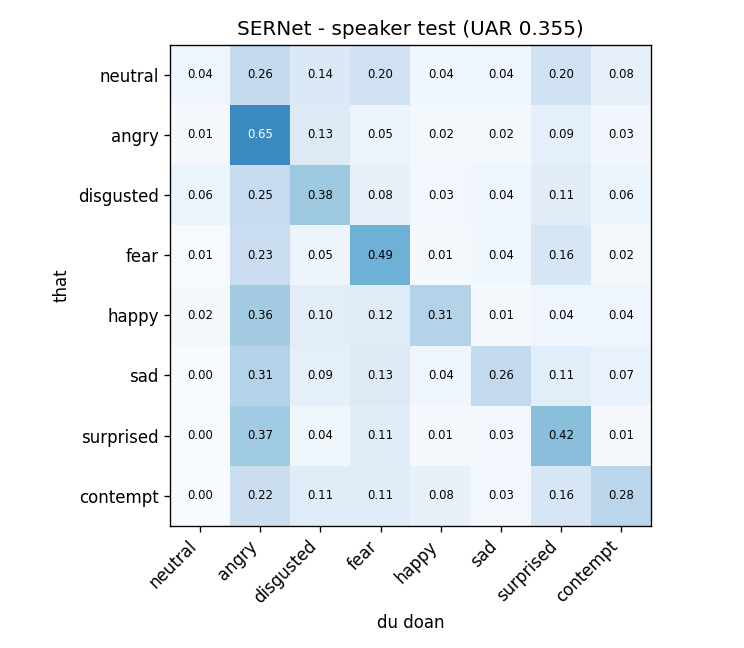

In [6]:
best_model, ck = S.load_sernet(OUT / 'ser_best.pth', DEVICE)
Xte, Ete, Lte, SPte = DATA['test']
Pt, Lvt = clip_probs(best_model, Xte)
mt = metrics(Pt, Ete, Lte, Lvt)
pred = Pt.argmax(1)
by_level = {int(l): round(float((pred[(Lte == l) & (Ete > 0)] == Ete[(Lte == l) & (Ete > 0)]).mean()), 3)
            for l in (1, 2, 3) if ((Lte == l) & (Ete > 0)).any()}
by_spk = {str(sp): round(float((pred[SPte == sp] == Ete[SPte == sp]).mean()), 3) for sp in sorted(set(SPte))}
cm = np.zeros((8, 8), int)
for a, b in zip(Ete, pred):
    cm[a, b] += 1
res = dict(epoch=ck['epoch'], test=mt, acc_by_level=by_level, acc_by_speaker=by_spk, confusion=cm.tolist(),
           labels=S.EMO_NAMES, chance_uar=0.125)
(OUT / 'ser_test_eval.json').write_text(json.dumps(res, indent=1))
print('TEST | acc %.3f | UAR %.3f (ngau nhien 0.125) | muc MAE %.2f' % (mt['acc'], mt['uar'], mt['level_mae'] or 0))
print('recall theo nhan:', mt['recall'])
print('acc theo muc (khong tinh neutral):', by_level)
print('acc theo speaker:', by_spk)

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(8)); ax.set_yticks(range(8))
ax.set_xticklabels(S.EMO_NAMES, rotation=45, ha='right'); ax.set_yticklabels(S.EMO_NAMES)
for i in range(8):
    for j in range(8):
        ax.text(j, i, '%.2f' % cmn[i, j], ha='center', va='center', fontsize=7, color='white' if cmn[i, j] > 0.5 else 'black')
ax.set_xlabel('du doan'); ax.set_ylabel('that'); ax.set_title('SERNet - speaker test (UAR %.3f)' % mt['uar'])
fig.tight_layout(); fig.savefig(OUT / 'ser_confusion_test.png', dpi=120); plt.close(fig)
if IN_COLAB:
    from IPython.display import Image, display
    display(Image(str(OUT / 'ser_confusion_test.png')))

## Cell 6 - (Tuy chon) So sanh voi emotion2vec+ tren audio goc MEAD cua speaker test

Lay ngau nhien `N_PER_SPEAKER` file `.m4a` trong `MEAD/<speaker>/audio.tar` (nhan lay tu ten thu muc). Ca hai mo
hinh doan tren **cung file**: SERNet tinh mel tu audio (giong luc dung that), emotion2vec+ nhan audio 16 kHz.
emotion2vec+ khong co nhan `contempt` -> so tren 7 nhan chung (bo clip contempt) va tren ca 8 nhan.

In [7]:
RUN_E2V = True
N_PER_SPEAKER = 150
if RUN_E2V:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'funasr', 'modelscope'], check=False)
    e2v = S.Emotion2VecSER(size='large', device=DEVICE.type)
    rows = []
    for sp in split['test']:
        tf = tarfile.open(MEAD_SRC / sp / 'audio.tar')
        mem = [m for m in tf.getmembers() if m.name.endswith('.m4a')]
        random.Random(0).shuffle(mem)
        for m in mem[:N_PER_SPEAKER]:
            parts = Path(m.name).parts                     # audio/<emo>/level_<l>/<id>.m4a
            emo, lvl = parts[-3], int(parts[-2].replace('level_', ''))
            tf.extract(m, '/tmp/ser_cmp', filter='data')
            y = A.load_wav_16k('/tmp/ser_cmp/' + m.name)
            mel = (A.mel_autovc(y) - MEL_MEAN) / MEL_STD
            _, p1, _ = S.sernet_windows(best_model, mel, win=C, hop=CFG['eval_hop'], device=DEVICE)
            p2 = e2v.predict(y)
            rows.append(dict(sp=sp, emo=S.EMO_NAMES.index(emo), lvl=lvl, ser=int(p1.mean(0).argmax()), e2v=int(p2.argmax())))
        print(sp, len(rows))
    E = np.array([r['emo'] for r in rows]); P1 = np.array([r['ser'] for r in rows]); P2 = np.array([r['e2v'] for r in rows])
    keep7 = E != 7

    def uar(e, p):
        return float(np.mean([(p[e == k] == k).mean() for k in np.unique(e)]))

    cmp_ = dict(n=len(rows), n_per_speaker=N_PER_SPEAKER,
                all8=dict(ser_acc=float((P1 == E).mean()), ser_uar=uar(E, P1), e2v_acc=float((P2 == E).mean()), e2v_uar=uar(E, P2)),
                shared7=dict(ser_acc=float((P1[keep7] == E[keep7]).mean()), ser_uar=uar(E[keep7], P1[keep7]),
                             e2v_acc=float((P2[keep7] == E[keep7]).mean()), e2v_uar=uar(E[keep7], P2[keep7])),
                recall_ser={S.EMO_NAMES[k]: round(float((P1[E == k] == k).mean()), 3) for k in np.unique(E)},
                recall_e2v={S.EMO_NAMES[k]: round(float((P2[E == k] == k).mean()), 3) for k in np.unique(E)})
    (OUT / 'ser_vs_emotion2vec.json').write_text(json.dumps(cmp_, indent=1))
    print(json.dumps({k: cmp_[k] for k in ('all8', 'shared7')}, indent=1))
    print('recall SERNet  :', cmp_['recall_ser'])
    print('recall e2v+    :', cmp_['recall_e2v'])

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


funasr version: 1.4.16.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.0.0.weight, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.0.0.bias, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.1.0.weight, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.1.0.bias, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.2.0.weight, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots